In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.model_selection import LeaveOneGroupOut, train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import RobustScaler
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from matplotlib import pyplot as plt

# AJOUTS pour l'imputation KNN, les pipelines et la comparaison
from sklearn.impute import KNNImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix

data = pd.read_csv("C:/Users/Administrateur/Desktop/Predection_IDS_Attaque/X-IIoTID dataset.csv")
print(f"Shape : {data.shape}")
print(f"\nColonnes :\n{data.columns.tolist()}")

Shape : (820834, 68)

Colonnes :
['Date', 'Timestamp', 'Scr_IP', 'Scr_port', 'Des_IP', 'Des_port', 'Protocol', 'Service', 'Duration', 'Scr_bytes', 'Des_bytes', 'Conn_state', 'missed_bytes', 'is_syn_only', 'Is_SYN_ACK', 'is_pure_ack', 'is_with_payload', 'FIN or RST', 'Bad_checksum', 'is_SYN_with_RST', 'Scr_pkts', 'Scr_ip_bytes', 'Des_pkts', 'Des_ip_bytes', 'anomaly_alert', 'total_bytes', 'total_packet', 'paket_rate', 'byte_rate', 'Scr_packts_ratio', 'Des_pkts_ratio', 'Scr_bytes_ratio', 'Des_bytes_ratio', 'Avg_user_time', 'Std_user_time', 'Avg_nice_time', 'Std_nice_time', 'Avg_system_time', 'Std_system_time', 'Avg_iowait_time', 'Std_iowait_time', 'Avg_ideal_time', 'Std_ideal_time', 'Avg_tps', 'Std_tps', 'Avg_rtps', 'Std_rtps', 'Avg_wtps', 'Std_wtps', 'Avg_ldavg_1', 'Std_ldavg_1', 'Avg_kbmemused', 'Std_kbmemused', 'Avg_num_Proc/s', 'Std_num_proc/s', 'Avg_num_cswch/s', 'std_num_cswch/s', 'OSSEC_alert', 'OSSEC_alert_level', 'Login_attempt', 'Succesful_login', 'File_activity', 'Process_activ

In [2]:
# Afficher toutes les colonnes (pandas en cache une partie par défaut)
pd.set_option("display.max_columns", None)
data.head(8)

,Date,Timestamp,Scr_IP,Scr_port,Des_IP,Des_port,Protocol,Service,Duration,Scr_bytes,Des_bytes,Conn_state,missed_bytes,is_syn_only,Is_SYN_ACK,is_pure_ack,is_with_payload,FIN or RST,Bad_checksum,is_SYN_with_RST,Scr_pkts,Scr_ip_bytes,Des_pkts,Des_ip_bytes,anomaly_alert,total_bytes,total_packet,paket_rate,byte_rate,Scr_packts_ratio,Des_pkts_ratio,Scr_bytes_ratio,Des_bytes_ratio,Avg_user_time,Std_user_time,Avg_nice_time,Std_nice_time,Avg_system_time,Std_system_time,Avg_iowait_time,Std_iowait_time,Avg_ideal_time,Std_ideal_time,Avg_tps,Std_tps,Avg_rtps,Std_rtps,Avg_wtps,Std_wtps,Avg_ldavg_1,Std_ldavg_1,Avg_kbmemused,Std_kbmemused,Avg_num_Proc/s,Std_num_proc/s,Avg_num_cswch/s,std_num_cswch/s,OSSEC_alert,OSSEC_alert_level,Login_attempt,Succesful_login,File_activity,Process_activity,read_write_physical.process,is_privileged,class1,class2,class3
0,9/01/2020,1578540956,192.168.2.199,49278,192.168.2.10,80,tcp,http,0.67369,13437,34924,1,0,True,True,True,True,True,False,False,105,18905,105,40392,TRUE,107658,210,311.7160712,159803.4704,0.5,0.5,0.300414275,0.699585725,9.207,5.55584206,10.994,1.356305275,4.864,1.873004004,0.311,0.224653066,74.624,8.245611196,12.297,10.38585004,8,10.50714043,4.297,2.723578712,2.146,0.102781321,915852.8,2507.97563,5.1,3.238826948,2806.2,158.7493622,1,5,0,0,0,0,0,0,Scanning_vulnerability,Reconnaissance,Attack
1,13/01/2020,1578871873,10.0.1.5,39769,131.236.3.92,53,udp,dns,0.000083,78,0,1,0,False,False,False,True,False,False,False,2,134,0,0,FALSE,212,2,24096.38554,2554216.867,1,0,1,0,12.326,6.674247823,2.895,1.604302029,3.778,2.099741889,2.741,5.327471164,78.263,8.869399134,6.6,5.713142743,0,0,6.6,5.713142743,0.612,0.037629775,910498.4,4044.112046,1,0.894427191,1561.6,247.0802299,0,0,0,0,0,0,0,0,Normal,Normal,Normal
2,9/01/2020,1578522486,172.24.1.80,59050,172.24.1.1,53,udp,dns,0.000132,38,38,1,0,False,False,False,True,False,False,False,1,66,1,66,FALSE,208,2,15151.51515,1575757.576,0.5,0.5,0.5,0.5,6.931,6.416007248,0.706,0.408905857,1.693,0.771635277,2.423,3.829809525,88.245,7.112108337,37.4,40.19004852,30.1,39.79811553,7.3,3.1,0.55,0.02,921020.4,2139.652645,1,0,1603.3,294.1390997,0,0,0,0,0,0,0,0,Normal,Normal,Normal
3,27/02/2020,1582757640,192.168.2.196,37966,192.168.2.10,1880,tcp,websocket,9.378481,1121,484,1,0,True,True,True,True,True,False,False,8,1545,6,804,FALSE,3954,14,1.492779055,421.6034558,0.571428571,0.428571429,0.67425392,0.32574608,10.244,7.932040343,1.965,1.514168088,3.941,1.709055002,0.509,0.425522032,83.339,10.20608686,29,26.57442379,23.3,26.12680616,5.7,6.229767251,0.708,0.026,915874.8,977.8851466,7.2,5.325410782,1685.3,467.8737116,0,0,1,1,1,1,1,1,Normal,Normal,Normal
4,16/12/2019,1576452612,172.24.1.80,38233,172.24.1.1,53,udp,dns,0.000074,-,-,1,0,False,False,False,True,False,False,False,-,-,-,-,FALSE,-,-,-,-,-,-,-,-,5.181,5.980458929,2.365,1.284462923,2.415,1.401151312,1.803,4.478256469,88.239,8.090017862,9.8,1.326649916,0.1,0.3,9.7,1.268857754,0.536,0.030066593,918213.2,2342.93836,0.6,0.489897949,1456.5,346.8847791,0,0,0,0,0,0,0,0,Normal,Normal,Normal
5,31/01/2020,1580452611,192.168.10.155,50502,192.168.2.10,80,tcp,http,5.153928,460,671,1,0,True,True,True,True,True,False,False,12,1560,10,1878,FALSE,4569,22,4.268588929,886.5083098,0.545454545,0.454545455,0.442109871,0.557890129,10.579,6.866914081,3.273,2.366140528,2.638,1.040920746,0.279,0.210829315,83.233,9.57921192,19.3,18.42308335,8.8,10.20588066,10.5,13.52959719,0.524,0.028,910370.8,4006.8817,0.9,0.538516481,1366.9,304.0626416,0,0,0,0,0,0,1,0,Normal,Normal,Normal
6,12/12/2019,1576100087,172.24.1.80,39649,172.24.1.1,53,udp,dns,0.000119,37,37,1,0,False,False,False,True,False,False,False,1,65,1,65,FALSE,204,2,16806.72269,1714285.714,0.5,0.5,0.5,0.5,2.47,4.589873637,2.292,1.712418173,2.552,0.949187021,0.504,1.098446175,92.183,5.98835712,10.3,7.523961722,5.1,6.425729531,5.2,5.035871325,0.44,0.02,907108,2995.482465,1,0,1185.5,188.0756497,0,0,0,0,0,0,0,0,Normal,Normal,Normal
7,21/02/2020,1582241330,172.24.1.34,52195,172.24.1.1,53,udp,dns,0.000184,36,3

In [3]:
# Dans ce dataset, "-" signifie "pas de valeur". Je le remplace par NaN
# pour que pandas le reconnaisse comme valeur manquante.
data = data.replace("-", np.nan)

In [4]:
data.info()

# Nombre de valeurs manquantes par colonne 
manquantes = data.isnull().sum()
pourcentage = (data.isnull().mean() * 100).round(2)

# Je regroupe les deux résultats dans un seul tableau
resume = pd.DataFrame({
    "Nb manquantes": manquantes,
    "Pourcentage (%)": pourcentage
})

# Je garde uniquement les colonnes qui ont des valeurs manquantes, triées de la plus touchée à la moins touchée
resume = resume[resume["Nb manquantes"] > 0].sort_values("Nb manquantes", ascending=False)

print("_______Les colonnes avec des valeurs manquantes_______")
print(resume)
print("\nNombre de colonnes concernées :", len(resume), "sur", data.shape[1])

<class 'pandas.DataFrame'>
RangeIndex: 820834 entries, 0 to 820833
Data columns (total 68 columns):
 #   Column                       Non-Null Count   Dtype
---  ------                       --------------   -----
 0   Date                         820503 non-null  str  
 1   Timestamp                    820537 non-null  str  
 2   Scr_IP                       820834 non-null  str  
 3   Scr_port                     820834 non-null  str  
 4   Des_IP                       820834 non-null  str  
 5   Des_port                     820834 non-null  str  
 6   Protocol                     820834 non-null  str  
 7   Service                      820834 non-null  str  
 8   Duration                     745073 non-null  str  
 9   Scr_bytes                    596963 non-null  str  
 10  Des_bytes                    596963 non-null  str  
 11  Conn_state                   820834 non-null  int64
 12  missed_bytes                 820680 non-null  str  
 13  is_syn_only                  820834 non-

In [5]:
# Colonnes qui restent en catégories ou identifiants
cols_texte = ["Scr_IP", "Des_IP", "Scr_port", "Des_port", "Protocol", "Service",
              "anomaly_alert", "class1", "class2", "class3", "Date", "Timestamp"]

# Je convertis en nombres les colonnes encore en texte (les valeurs invalides deviennent NaN)
for c in data.columns:
    if c not in cols_texte and not pd.api.types.is_numeric_dtype(data[c]):
        data[c] = pd.to_numeric(data[c], errors="coerce")

# Les trois groupes de colonnes qui manquent ensemble
grp_A = ["Scr_bytes", "Des_bytes", "total_bytes", "paket_rate", "byte_rate",
         "Scr_bytes_ratio", "Des_bytes_ratio"]
grp_B = ["Scr_pkts", "Des_pkts", "Scr_ip_bytes", "Des_ip_bytes",
         "total_packet", "Scr_packts_ratio", "Des_pkts_ratio"]
grp_C = ["Duration"]

# Indicateur par groupe : True si au moins une valeur du groupe manque sur la ligne
ind = pd.DataFrame({
    "A_octets":  data[grp_A].isnull().any(axis=1),
    "B_paquets": data[grp_B].isnull().any(axis=1),
    "C_duration": data[grp_C].isnull().any(axis=1),
})
print(ind.mean().round(4) * 100)   # pourcentage de lignes touchées par groupe

A_octets      27.27
B_paquets     18.61
C_duration     9.23
dtype: float64


In [6]:
# Pourcentage de manquants par colonne (recalculé APRÈS la conversion des types)
pourcentage = data.isnull().mean() * 100

# Règle :  < 5 % -> supprimer les lignes | > 50 % -> supprimer la colonne | entre les deux -> imputer
cols_moins_5 = pourcentage[(pourcentage > 0) & (pourcentage < 5)].index.tolist()
cols_plus_50 = pourcentage[pourcentage > 50].index.tolist()
cols_a_imputer = pourcentage[(pourcentage >= 5) & (pourcentage <= 50)].index.tolist()

print("Colonnes < 5 % (suppression des lignes) :", cols_moins_5)
print("Colonnes > 50 % (suppression de la colonne) :", cols_plus_50)
print("Colonnes entre 5 % et 50 % (imputation KNN / médiane) :", cols_a_imputer)

avant = len(data)
data = data.drop(columns=cols_plus_50)                       # liste normalement vide ici
data = data.dropna(subset=cols_moins_5).reset_index(drop=True)
print("Lignes supprimées :", avant - len(data))

Colonnes < 5 % (suppression des lignes) : ['Date', 'Timestamp', 'missed_bytes', 'anomaly_alert', 'Avg_user_time', 'Std_user_time', 'Avg_nice_time', 'Std_nice_time', 'Avg_system_time', 'Std_system_time', 'Avg_iowait_time', 'Std_iowait_time', 'Avg_ideal_time', 'Std_ideal_time', 'Avg_tps', 'Std_tps', 'Avg_rtps', 'Std_rtps', 'Avg_wtps', 'Std_wtps', 'Avg_ldavg_1', 'Std_ldavg_1', 'Avg_kbmemused', 'Std_kbmemused', 'Avg_num_Proc/s', 'Std_num_proc/s', 'Avg_num_cswch/s', 'std_num_cswch/s']
Colonnes > 50 % (suppression de la colonne) : []
Colonnes entre 5 % et 50 % (imputation KNN / médiane) : ['Duration', 'Scr_bytes', 'Des_bytes', 'Scr_pkts', 'Scr_ip_bytes', 'Des_pkts', 'Des_ip_bytes', 'total_bytes', 'total_packet', 'paket_rate', 'byte_rate', 'Scr_packts_ratio', 'Des_pkts_ratio', 'Scr_bytes_ratio', 'Des_bytes_ratio']
Lignes supprimées : 1652


***Remarque :***
Date et Timestamp ont 0,04 % de valeurs manquantes (moins de 5 %) : je supprime ces lignes.
15 autres colonnes ont entre 9 % et 28 % de valeurs manquantes (entre 5 % et 50 %) : je les impute, avec KNN et avec la médiane, puis je compare les deux.
Aucune colonne ne dépasse 50 %.

In [7]:
# Date et Timestamp ont 0,04 % de valeurs manquantes, soit moins de 5 % : leurs lignes ont déjà
# été supprimées dans la cellule précédente. Je vérifie qu'il n'en reste plus.
# Règle : moins de 5 % = suppression des lignes ; plus de 50 % = suppression de la colonne ;
# entre les deux = imputation selon le mécanisme (MCAR : moyenne/médiane, MAR : KNN/MICE,
# MNAR : colonne indicateur).
cols = ["Date", "Timestamp"]
print(data[cols].isnull().sum())

Date         0
Timestamp    0
dtype: int64


In [8]:
# Le dataset complet a 820 834 lignes, ce qui rend les calculs lents.
# Je travaille sur un échantillon aléatoire stratifié de 200 lignes, pour garder
# les mêmes proportions de classes que le dataset complet.
# La cible est class3 : je stratifie donc sur class3 (et non plus sur class1).
# random_state=42 permet d'obtenir toujours le même échantillon.
print(data["class3"].value_counts())

data_small, _ = train_test_split(
    data, train_size=200, stratify=data["class3"], random_state=42
)
data_small = data_small.reset_index(drop=True)

print(data_small.shape)
print(data_small["class1"].value_counts())
print(data_small["class3"].value_counts())

# Je sauvegarde l'échantillon dans un fichier CSV pour pouvoir le réutiliser
# sans recharger le dataset complet.
data_small.to_csv(
    "C:/Users/Administrateur/Desktop/Predection_IDS_Attaque/data_small_200.csv",
    index=False
)
print("Fichier sauvegardé.")

class3
Normal    420674
Attack    398508
Name: count, dtype: int64
(200, 68)
class1
Normal                            103
RDOS                               35
Scanning_vulnerability             12
MQTT_cloud_broker_subscription      9
Generic_scanning                    8
Exfiltration                        8
BruteForce                          7
insider_malcious                    6
Discovering_resources               4
Modbus_register_reading             3
Dictionary                          2
False_data_injection                2
fuzzing                             1
Name: count, dtype: int64
class3
Normal    103
Attack     97
Name: count, dtype: int64
Fichier sauvegardé.


In [9]:
data_small.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 68 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Date                         200 non-null    str    
 1   Timestamp                    200 non-null    str    
 2   Scr_IP                       200 non-null    str    
 3   Scr_port                     200 non-null    str    
 4   Des_IP                       200 non-null    str    
 5   Des_port                     200 non-null    str    
 6   Protocol                     200 non-null    str    
 7   Service                      200 non-null    str    
 8   Duration                     186 non-null    float64
 9   Scr_bytes                    154 non-null    float64
 10  Des_bytes                    154 non-null    float64
 11  Conn_state                   200 non-null    int64  
 12  missed_bytes                 200 non-null    float64
 13  is_syn_only                  20

***Remarque :***
Dans l'échantillon, `Date` et `Timestamp` sont de type texte alors que ce sont des dates : je les convertis.
Les autres colonnes numériques ont déjà été converties avant l'échantillonnage (cellule 5).

In [10]:
# Date : format jour/mois/année. Le "if" évite de convertir deux fois si je relance la cellule.
if not pd.api.types.is_datetime64_any_dtype(data_small["Date"]):
    data_small["Date"] = pd.to_datetime(data_small["Date"], dayfirst=True, errors="coerce")

# Timestamp : temps Unix en secondes (10 chiffres)
if not pd.api.types.is_datetime64_any_dtype(data_small["Timestamp"]):
    data_small["Timestamp"] = pd.to_datetime(
        pd.to_numeric(data_small["Timestamp"], errors="coerce"), unit="s", errors="coerce"
    )

# Vérification : on doit obtenir 0 et 0
print(data_small[["Date", "Timestamp"]].isnull().sum())
print(data_small[["Date", "Timestamp"]].head())

Date         0
Timestamp    0
dtype: int64
        Date           Timestamp
0 2020-01-08 2020-01-08 02:29:43
1 2020-02-18 2020-02-18 07:45:20
2 2020-01-13 2020-01-13 00:11:40
3 2020-01-15 2020-01-15 04:52:24
4 2019-12-16 2019-12-16 01:05:04


In [11]:
# J'extrais l'information temporelle utile AVANT de supprimer les colonnes d'origine.
# Je ne garde ni le mois ni l'année : les données couvrent seulement 4 mois (déc. 2019 - mars 2020),
# donc ces colonnes indiqueraient la période de capture et non le comportement d'une attaque.
heure = data_small["Timestamp"].dt.hour
jour_semaine = data_small["Timestamp"].dt.dayofweek   # 0 = lundi

# Encodage cyclique : 23h et 0h (ou dimanche et lundi) deviennent voisins
data_small["heure_sin"] = np.sin(2 * np.pi * heure / 24)
data_small["heure_cos"] = np.cos(2 * np.pi * heure / 24)
data_small["jour_sin"] = np.sin(2 * np.pi * jour_semaine / 7)
data_small["jour_cos"] = np.cos(2 * np.pi * jour_semaine / 7)

# Date est redondante avec Timestamp, et les deux risquent de faire mémoriser
# les dates au modèle au lieu d'apprendre le comportement des attaques.
data_small = data_small.drop(columns=["Date", "Timestamp"], errors="ignore")
print(data_small.shape)   # 68 - 2 + 4 = 70 colonnes

(200, 70)


C:\Users\Administrateur\AppData\Local\Temp\ipykernel_9240\2905015384.py:5: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  jour_semaine = data_small["Timestamp"].dt.dayofweek   # 0 = lundi


## Gestion des valeurs manquantes : médiane ou KNN ?

**Règle appliquée** : moins de 5 % de manquants, je supprime les lignes (fait sur le dataset complet) ; entre 5 % et 50 %, j'impute ; plus de 50 %, je supprime la colonne.

Les 15 colonnes à imputer manquent ensemble, par 3 groupes (octets/débits : 27,27 % ; paquets : 18,61 % ; durée : 9,23 %). L'absence dépend d'autres colonnes (MAR) : **KNN** est donc adapté, mais je le compare à la **médiane**, plus simple et plus rapide.

Ordre : j'ajoute les indicateurs « valeur manquante », je sépare Train/Test, puis j'impute avec `fit` sur Train uniquement, pour éviter la fuite de données.

In [12]:
# Colonnes retirées : IP et ports (risque de mémorisation).
data_small = data_small.drop(columns=["Scr_IP", "Des_IP", "Scr_port", "Des_port"])

# anomaly_alert : TRUE/FALSE -> 1/0 ; les booléens -> 0/1
data_small["anomaly_alert"] = (
    data_small["anomaly_alert"].astype(str).str.upper()
    .map({"TRUE": 1, "FALSE": 0, "1": 1, "0": 0})
)
bool_cols = data_small.select_dtypes("bool").columns
data_small[bool_cols] = data_small[bool_cols].astype(int)

data_small.info()
data_small.describe()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 66 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Protocol                     200 non-null    str    
 1   Service                      200 non-null    str    
 2   Duration                     186 non-null    float64
 3   Scr_bytes                    154 non-null    float64
 4   Des_bytes                    154 non-null    float64
 5   Conn_state                   200 non-null    int64  
 6   missed_bytes                 200 non-null    float64
 7   is_syn_only                  200 non-null    int64  
 8   Is_SYN_ACK                   200 non-null    int64  
 9   is_pure_ack                  200 non-null    int64  
 10  is_with_payload              200 non-null    int64  
 11  FIN or RST                   200 non-null    int64  
 12  Bad_checksum                 200 non-null    int64  
 13  is_SYN_with_RST              20

,Duration,Scr_bytes,Des_bytes,Conn_state,missed_bytes,is_syn_only,Is_SYN_ACK,is_pure_ack,is_with_payload,FIN or RST,Bad_checksum,is_SYN_with_RST,Scr_pkts,Scr_ip_bytes,Des_pkts,Des_ip_bytes,anomaly_alert,total_bytes,total_packet,paket_rate,byte_rate,Scr_packts_ratio,Des_pkts_ratio,Scr_bytes_ratio,Des_bytes_ratio,Avg_user_time,Std_user_time,Avg_nice_time,Std_nice_time,Avg_system_time,Std_system_time,Avg_iowait_time,Std_iowait_time,Avg_ideal_time,Std_ideal_time,Avg_tps,Std_tps,Avg_rtps,Std_rtps,Avg_wtps,Std_wtps,Avg_ldavg_1,Std_ldavg_1,Avg_kbmemused,Std_kbmemused,Avg_num_Proc/s,Std_num_proc/s,Avg_num_cswch/s,std_num_cswch/s,OSSEC_alert,OSSEC_alert_level,Login_attempt,Succesful_login,File_activity,Process_activity,read_write_physical.process,is_privileged,heure_sin,heure_cos,jour_sin,jour_cos
count,186.000000,154.000000,154.000000,200.000000,200.0,200.00000,200.000000,200.000000,200.000000,200.000000,200.0,200.0,168.000000,168.000000,168.000000,1.680000e+02,200.000000,1.540000e+02,168.000000,154.000000,1.540000e+02,168.000000,168.000000,154.000000,154.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000
mean,6.214123,1901.753247,32427.175325,0.870000,0.0,0.50500,0.395000,0.395000,0.875000,0.485000,0.0,0.0,30.267857,3250.934524,41.892857,3.526371e+04,0.140000,7.629812e+04,72.160714,35131.424584,4.213623e+06,0.655704,0.344296,0.600314,0.399686,10.257303,5.810109,2.455453,1.462969,4.602975,1.549846,2.319810,4.028530,80.365205,9.485121,15.648995,13.271099,7.378608,10.218006,8.270387,5.409649,0.963792,0.057088,913334.456600,4549.957586,1518.704405,2146.888272,4031.892117,671.413419,0.050000,0.250000,0.125000,0.115000,0.100000,0.115000,0.375000,0.115000,0.338187,0.656327,0.331608,0.295116
std,13.118561,5699.199722,127137.470720,0.337147,0.0,0.50123,0.490077,0.490077,0.331549,0.501029,0.0,0.0,91.613381,8179.382207,137.319813,1.500438e+05,0.347858,2.886338e+05,226.480078,115035.159028,1.450654e+07,0.226218,0.226218,0.305961,0.305961,8.993106,2.461502,1.757318,0.848564,4.547723,0.837664,3.710314,6.060382,13.581545,4.740503,10.312986,14.000738,9.758584,14.938848,4.256443,4.964284,0.621473,0.076695,22478.055828,30217.354030,21455.772873,30342.807339,5414.236864,987.284414,0.218492,1.092459,0.331549,0.319823,0.300753,0.319823,0.485338,0.319823,0.519760,0.432435,0.526599,0.727785
min,0.000003,0.000000,0.000000,0.000000,0.0,0.00000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,1.000000,38.000000,0.000000,0.000000e+00,0.000000,8.400000e+01,1.000000,0.046726,2.793560e+01,0.301565,0.000000,0.011833,0.000000,0.533000,0.332116,0.529000,0.255517,0.937000,0.317578,0.026000,0.078000,41.376000,0.464479,2.997000,0.000000,0.000000,0.000000,1.700000,0.000000,0.113000,0.000000,607124.120000,134.319619,0.000000,0.000000,787.800000,81.808863,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.866025,-0.707107,-0.974928,-0.900969
25%,0.000208,58.250000,0.000000,1.000000,0.0,0.00000,0.000000,0.000000,1.000000,0.000000,0.0,0.0,1.000000,133.000000,0.000000,0.000000e+00,0.000000,2.200000e+02,2.000000,5.356387,2.337495e+03,0.500000,0.000000,0.434309,0.069467,4.229750,4.323876,1.631500,0.952415,2.098750,0.997880,0.278500,0.197222,76.592000,6.847115,9.475000,4.671586,0.100000,0.300000,3.700000,1.417745,0.517500,0.021581,912995.200000,1624.632338,0.500000,0.400000,1329.400000,238.022038,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.000000,-0.222521
50%,0.011364,156.000000,72.000000,1.000000,0.0,1.00000,0.000000,0.000000,1.000000,0.000000,0.0,0.0,2.000000,590.000000,1.000000,1.000000e+02,0.000000,1.685000e+03,3.000000,653.201623,1.590640e+05,0.545455,0.454545,

## Visualisation avant la séparation Train/Test

Je regarde la cible `class3`, l'asymétrie (skew) des features et leurs valeurs extrêmes (boxplots). Ces graphiques servent à **décider** des transformations (log, scaler). Je ne les applique pas ici : toute transformation sera apprise sur Train uniquement, dans le Pipeline.

        Dataset complet  % complet  Échantillon  % échantillon
class3                                                        
Normal           420674      51.35          103           51.5
Attack           398508      48.65           97           48.5

Nombre de classes : 2
Rapport de déséquilibre (échantillon) : 1.1


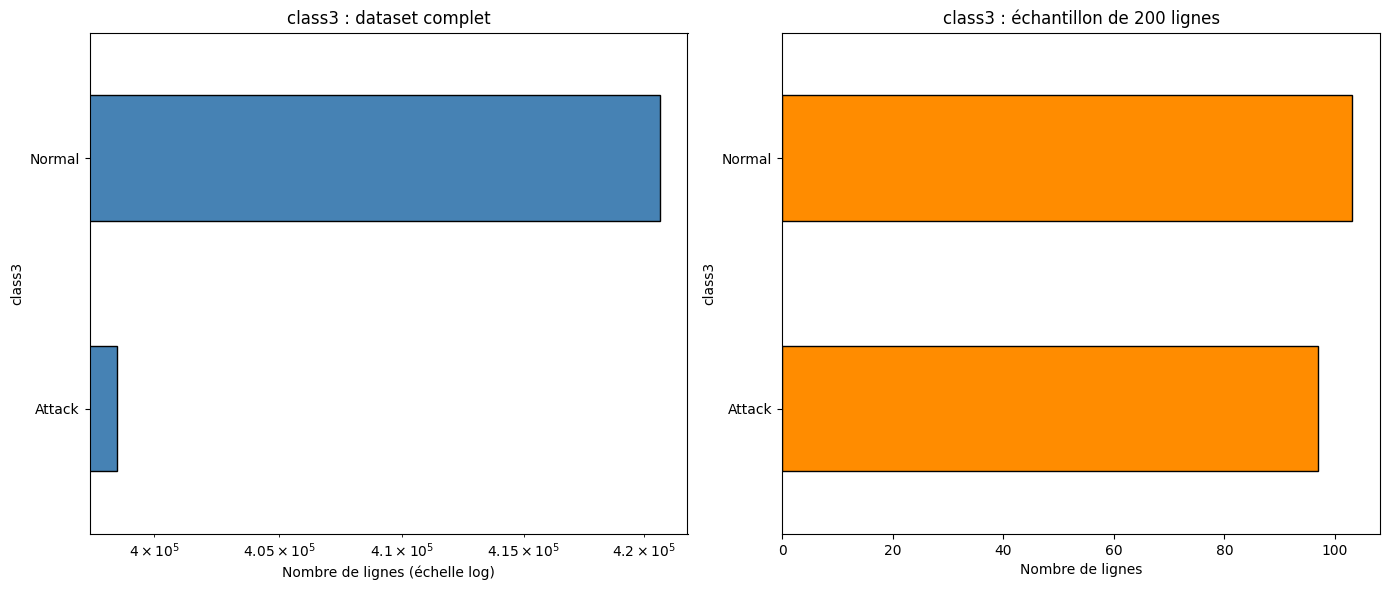

In [13]:
# Répartition de class3 : dataset complet (après nettoyage) et échantillon de 200 lignes

# Sécurité : y est normalement défini dans la cellule qui crée X et y
if "y" not in globals():
    y = data_small["class3"]

complet = data["class3"].value_counts()   # dataset complet (et non data_small)
echant = y.value_counts()                 # échantillon de 200 lignes

tab_classes = pd.DataFrame({
    "Dataset complet": complet,
    "% complet": (complet / complet.sum() * 100).round(2),
    "Échantillon": echant,
    "% échantillon": (echant / echant.sum() * 100).round(2),
}).fillna(0)
print(tab_classes.sort_values("Dataset complet", ascending=False))

# Rapport entre la plus grande et la plus petite classe de l'échantillon
print("\nNombre de classes :", y.nunique())
print("Rapport de déséquilibre (échantillon) :", round(echant.max() / echant.min(), 1))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

complet.sort_values().plot(kind="barh", ax=axes[0], color="steelblue", edgecolor="k")
axes[0].set_title("class3 : dataset complet")
axes[0].set_xlabel("Nombre de lignes (échelle log)")
axes[0].set_xscale("log")   # l'échelle log permet de voir aussi les classes rares

echant.sort_values().plot(kind="barh", ax=axes[1], color="darkorange", edgecolor="k")
axes[1].set_title("class3 : échantillon de 200 lignes")
axes[1].set_xlabel("Nombre de lignes")

plt.tight_layout()
plt.show()

In [14]:
# Les colonnes binaires (0/1) n'ont pas d'asymétrie utile à regarder : je les mets à part.

# Sécurité : X est normalement défini dans la cellule qui retire class1, class2, class3
if "X" not in globals():
    X = data_small.drop(columns=["class1", "class2", "class3"])

num_all = X.select_dtypes("number").columns.tolist()
cont = [c for c in num_all if X[c].nunique() > 2]
binaires = [c for c in num_all if X[c].nunique() <= 2]

print("Features continues :", len(cont))
print("Features binaires  :", len(binaires))
print("Catégorielles      :", X.select_dtypes(exclude="number").columns.tolist())

# Fonction pour afficher les graphiques en grille : 9 par page (3 par ligne) pour rester lisible
def grille(cols, tracer, titre, par_page=9, ncols=3):
    for debut in range(0, len(cols), par_page):
        sous = cols[debut:debut + par_page]
        nrows = int(np.ceil(len(sous) / ncols))
        fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4.5 * nrows))
        axes = np.array(axes).reshape(-1)
        for ax, c in zip(axes, sous):
            tracer(ax, c)
            ax.tick_params(axis="x", labelsize=8, rotation=30)   # évite le chevauchement des valeurs sur l'axe x
            ax.tick_params(axis="y", labelsize=8)
        for ax in axes[len(sous):]:
            ax.axis("off")
        fig.suptitle(f"{titre} ({debut + 1} à {debut + len(sous)} sur {len(cols)})", fontsize=15)
        plt.tight_layout(rect=[0, 0, 1, 0.95], h_pad=3, w_pad=3)   # espace entre les graphiques + place pour le titre
        plt.show()

Features continues : 43
Features binaires  : 18
Catégorielles      : ['Protocol', 'Service']


In [15]:
# Skew : 0 = symétrique ; > 0 = queue vers la droite (quelques très grandes valeurs) ; < 0 = queue vers la gauche
skew_tab = X[cont].skew().sort_values(key=abs, ascending=False).round(2)

def lire_skew(s):
    a = abs(s)
    if a < 0.5:
        return "Symétrique"
    elif a < 1:
        return "Asymétrie modérée"
    return "Très asymétrique"

resume_skew = pd.DataFrame({"Skew": skew_tab, "Lecture": skew_tab.apply(lire_skew)})
print(resume_skew)
print("\nColonnes très asymétriques (|skew| >= 1) :", (skew_tab.abs() >= 1).sum(), "sur", len(skew_tab))

                   Skew            Lecture
Std_num_proc/s    14.14   Très asymétrique
Avg_num_Proc/s    14.14   Très asymétrique
Std_kbmemused     14.10   Très asymétrique
Avg_kbmemused    -12.87   Très asymétrique
Des_ip_bytes       5.26   Très asymétrique
Scr_bytes          5.22   Très asymétrique
byte_rate          4.51   Très asymétrique
Std_ldavg_1        4.41   Très asymétrique
total_bytes        4.38   Très asymétrique
paket_rate         4.34   Très asymétrique
Des_bytes          4.23   Très asymétrique
Des_pkts           4.07   Très asymétrique
total_packet       3.90   Très asymétrique
Scr_pkts           3.90   Très asymétrique
Avg_iowait_time    3.78   Très asymétrique
Scr_ip_bytes       3.57   Très asymétrique
Avg_system_time    3.52   Très asymétrique
std_num_cswch/s    3.52   Très asymétrique
Avg_nice_time      3.50   Très asymétrique
Std_tps            3.21   Très asymétrique
Std_rtps           3.16   Très asymétrique
Duration           2.83   Très asymétrique
Avg_rtps   

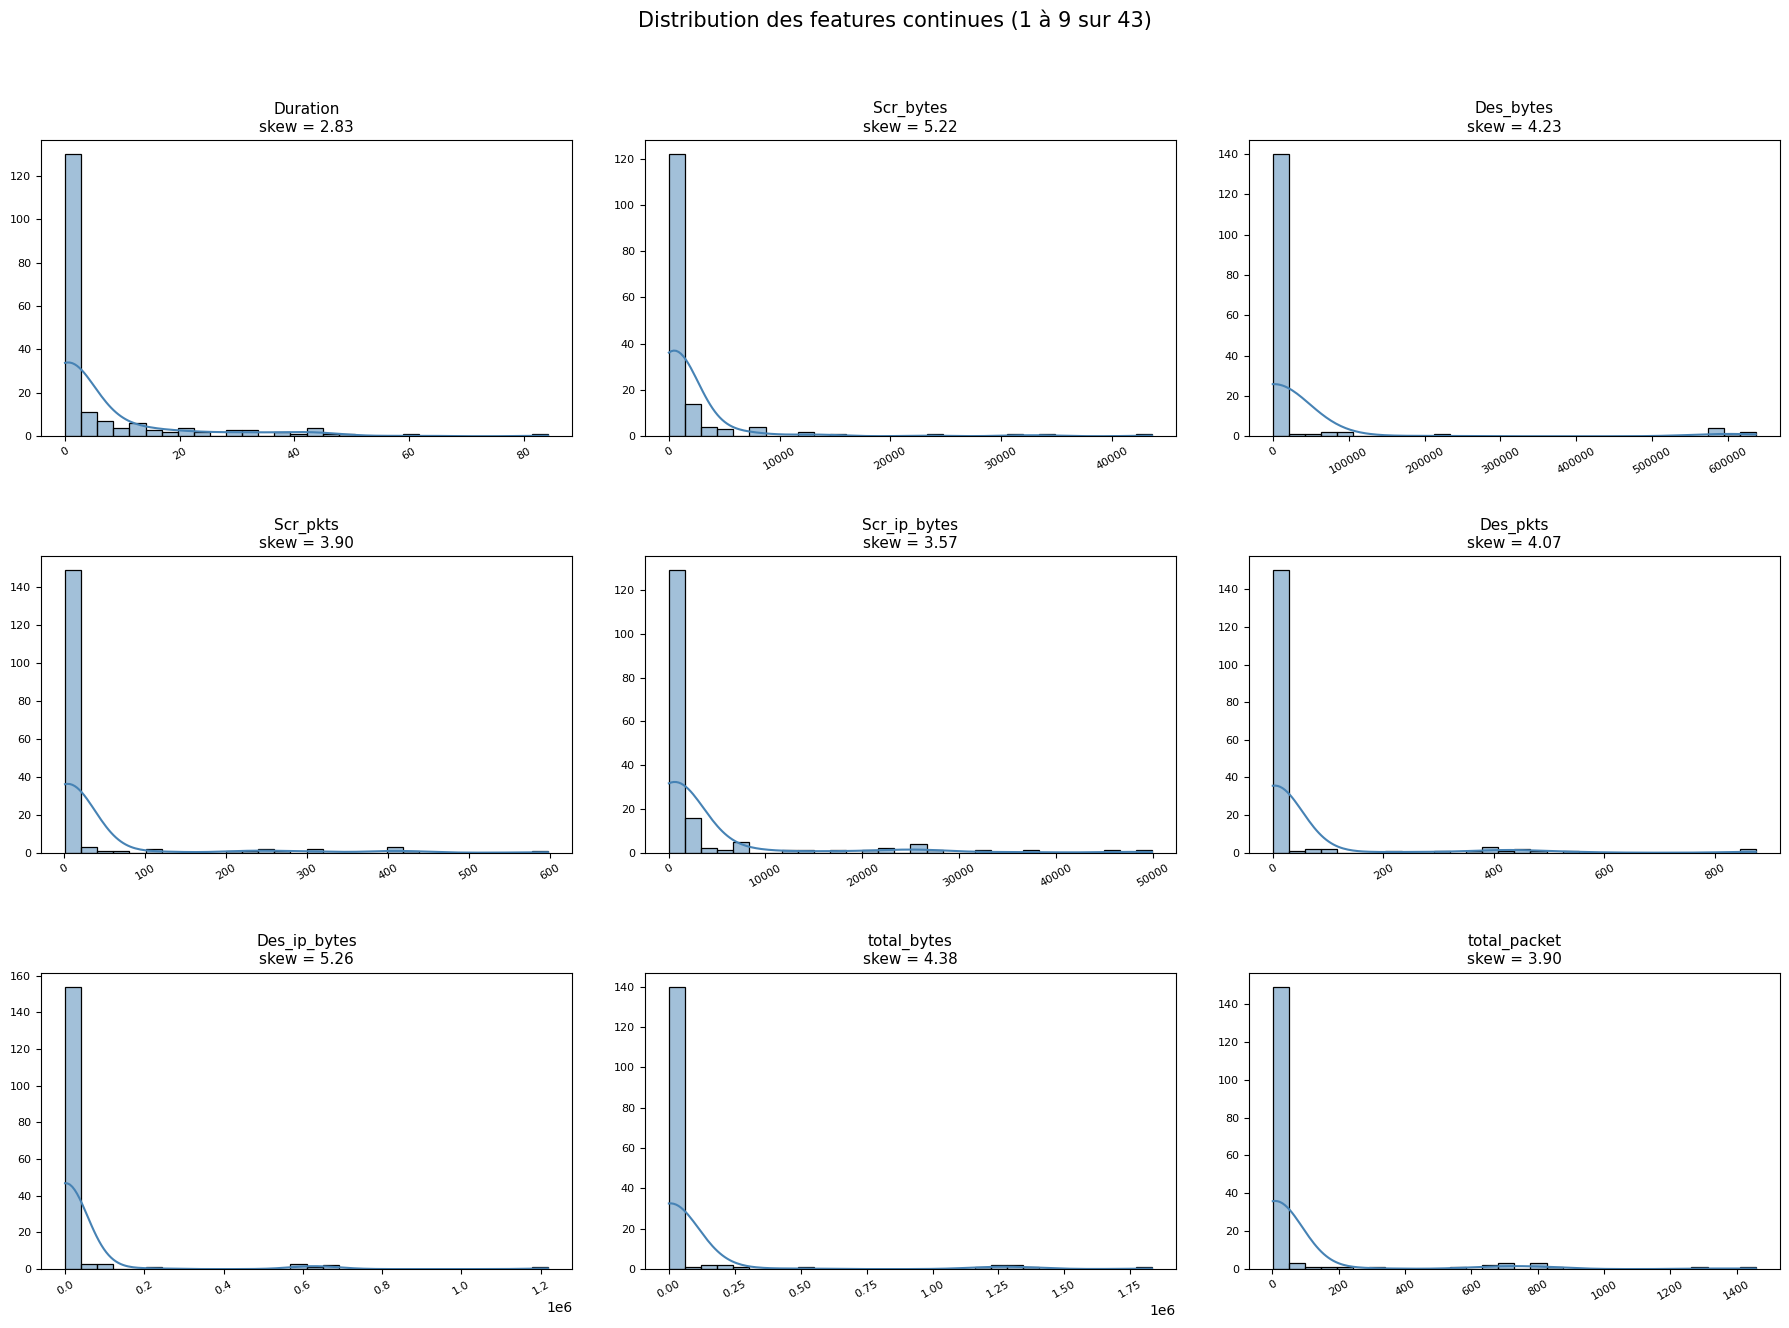

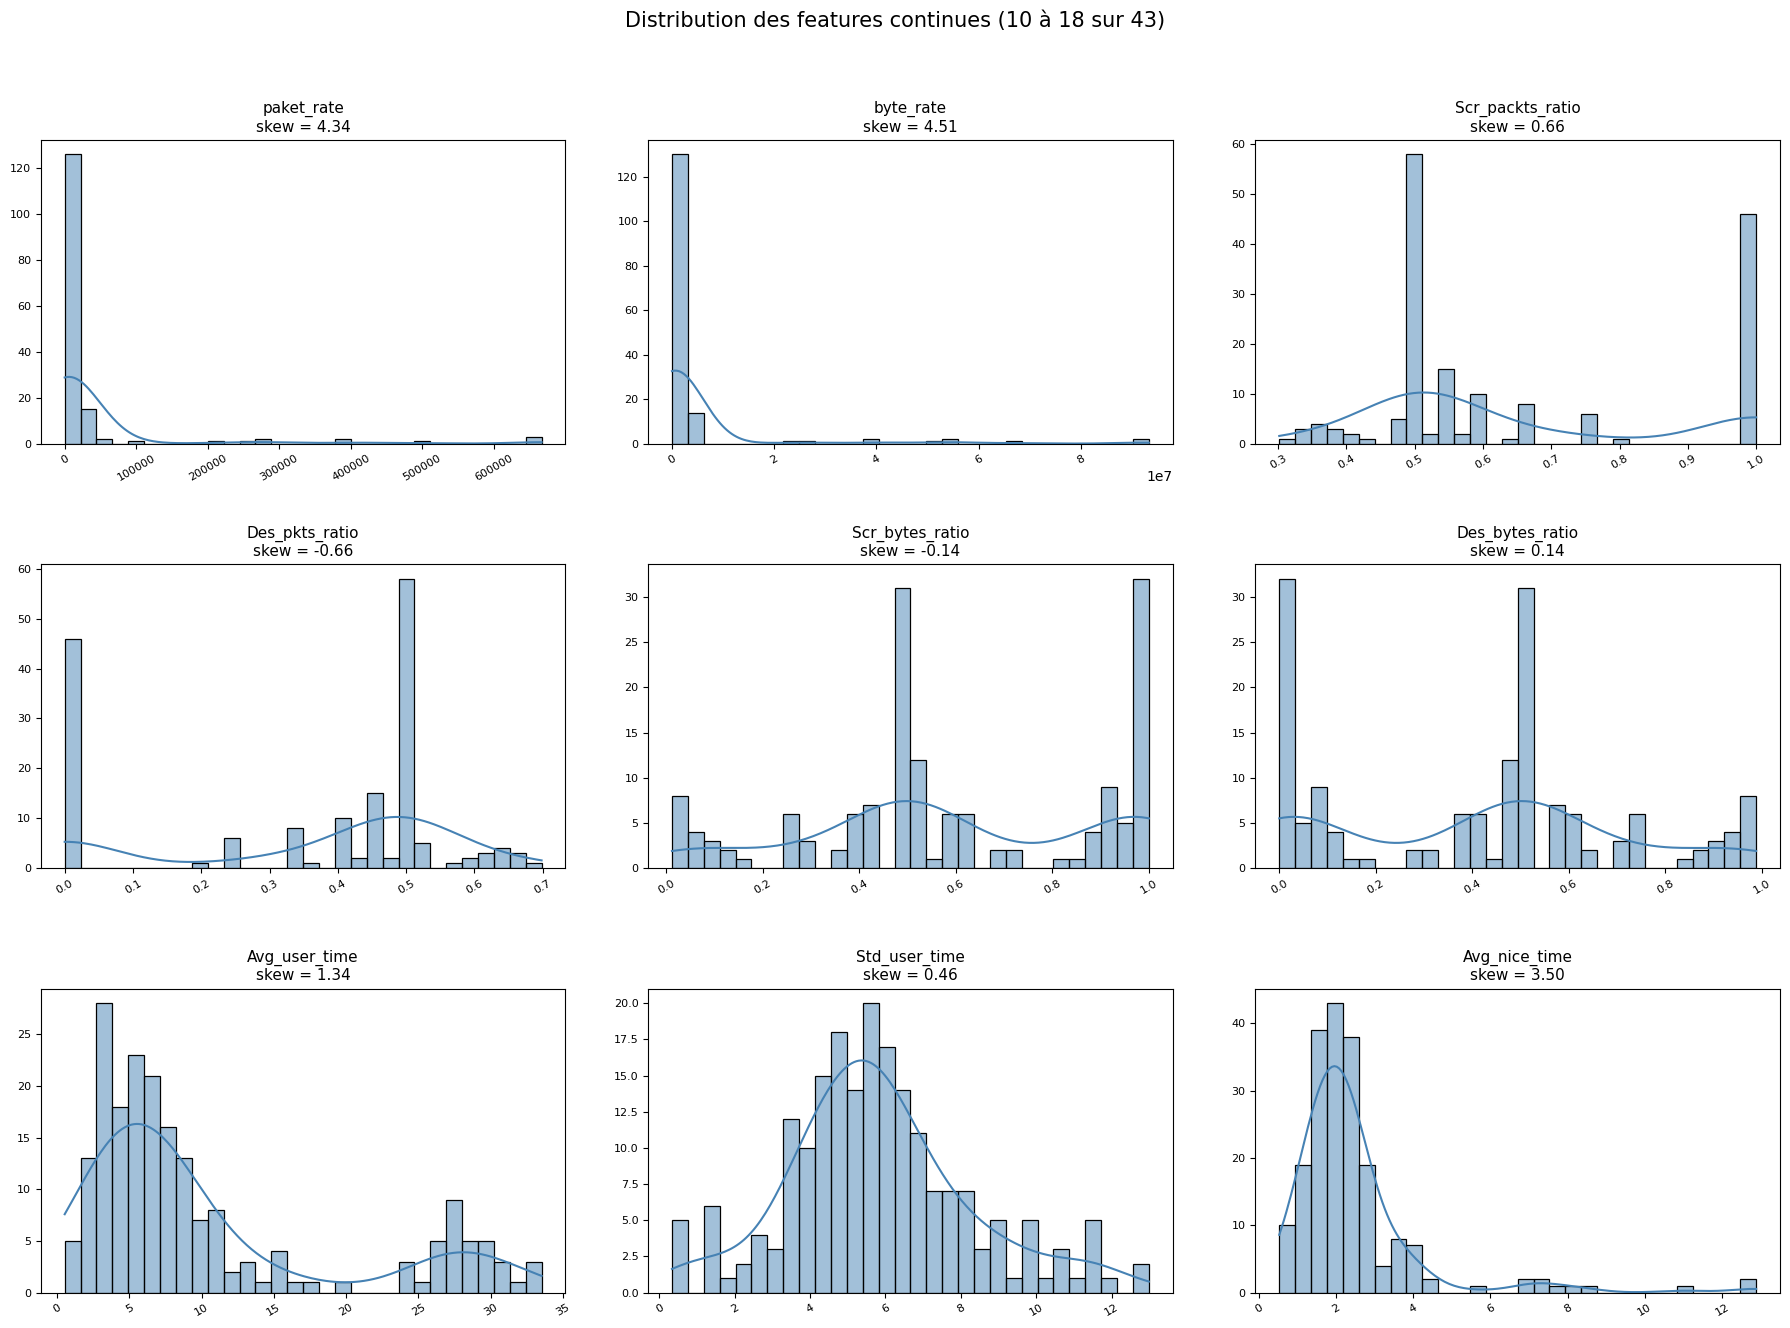

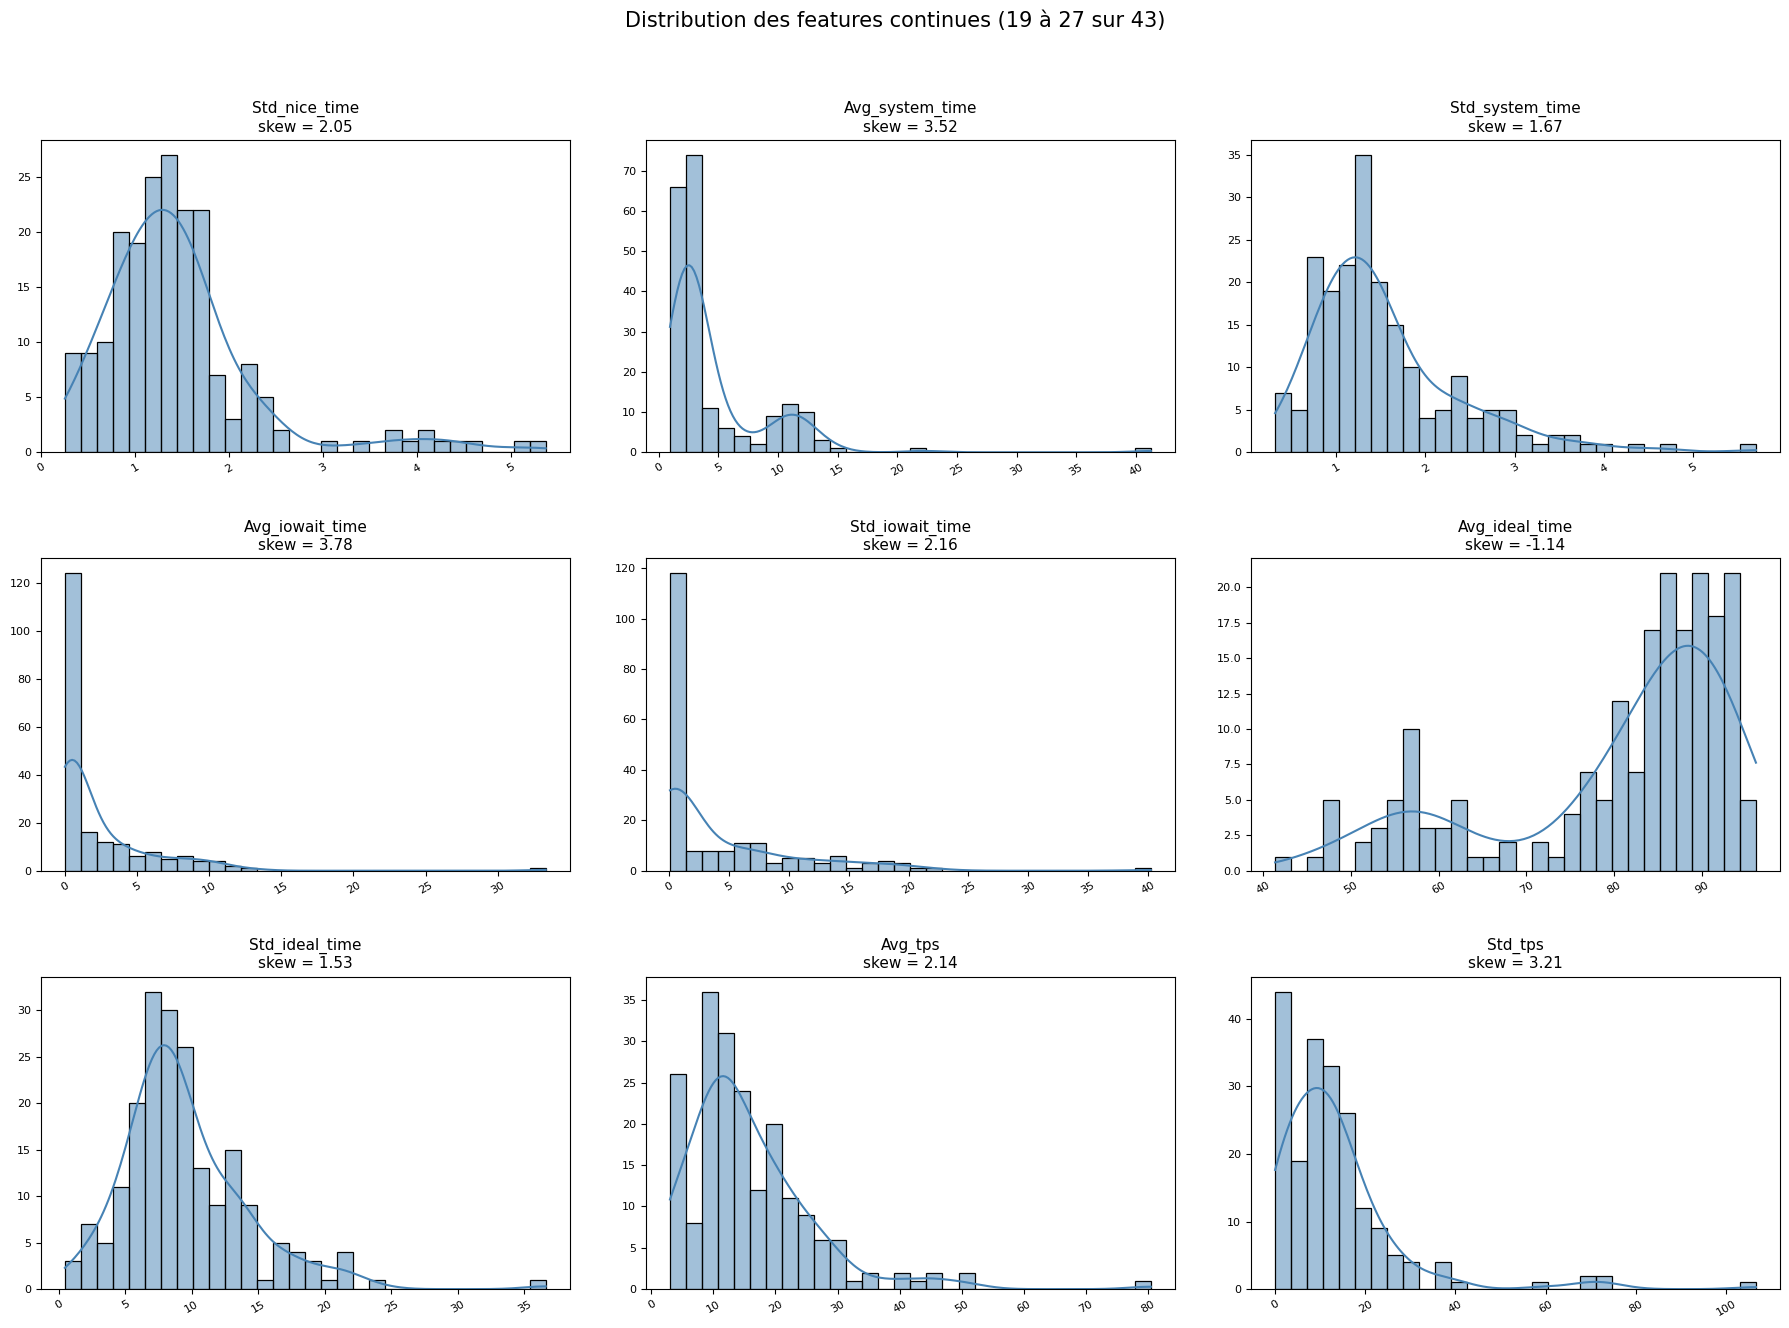

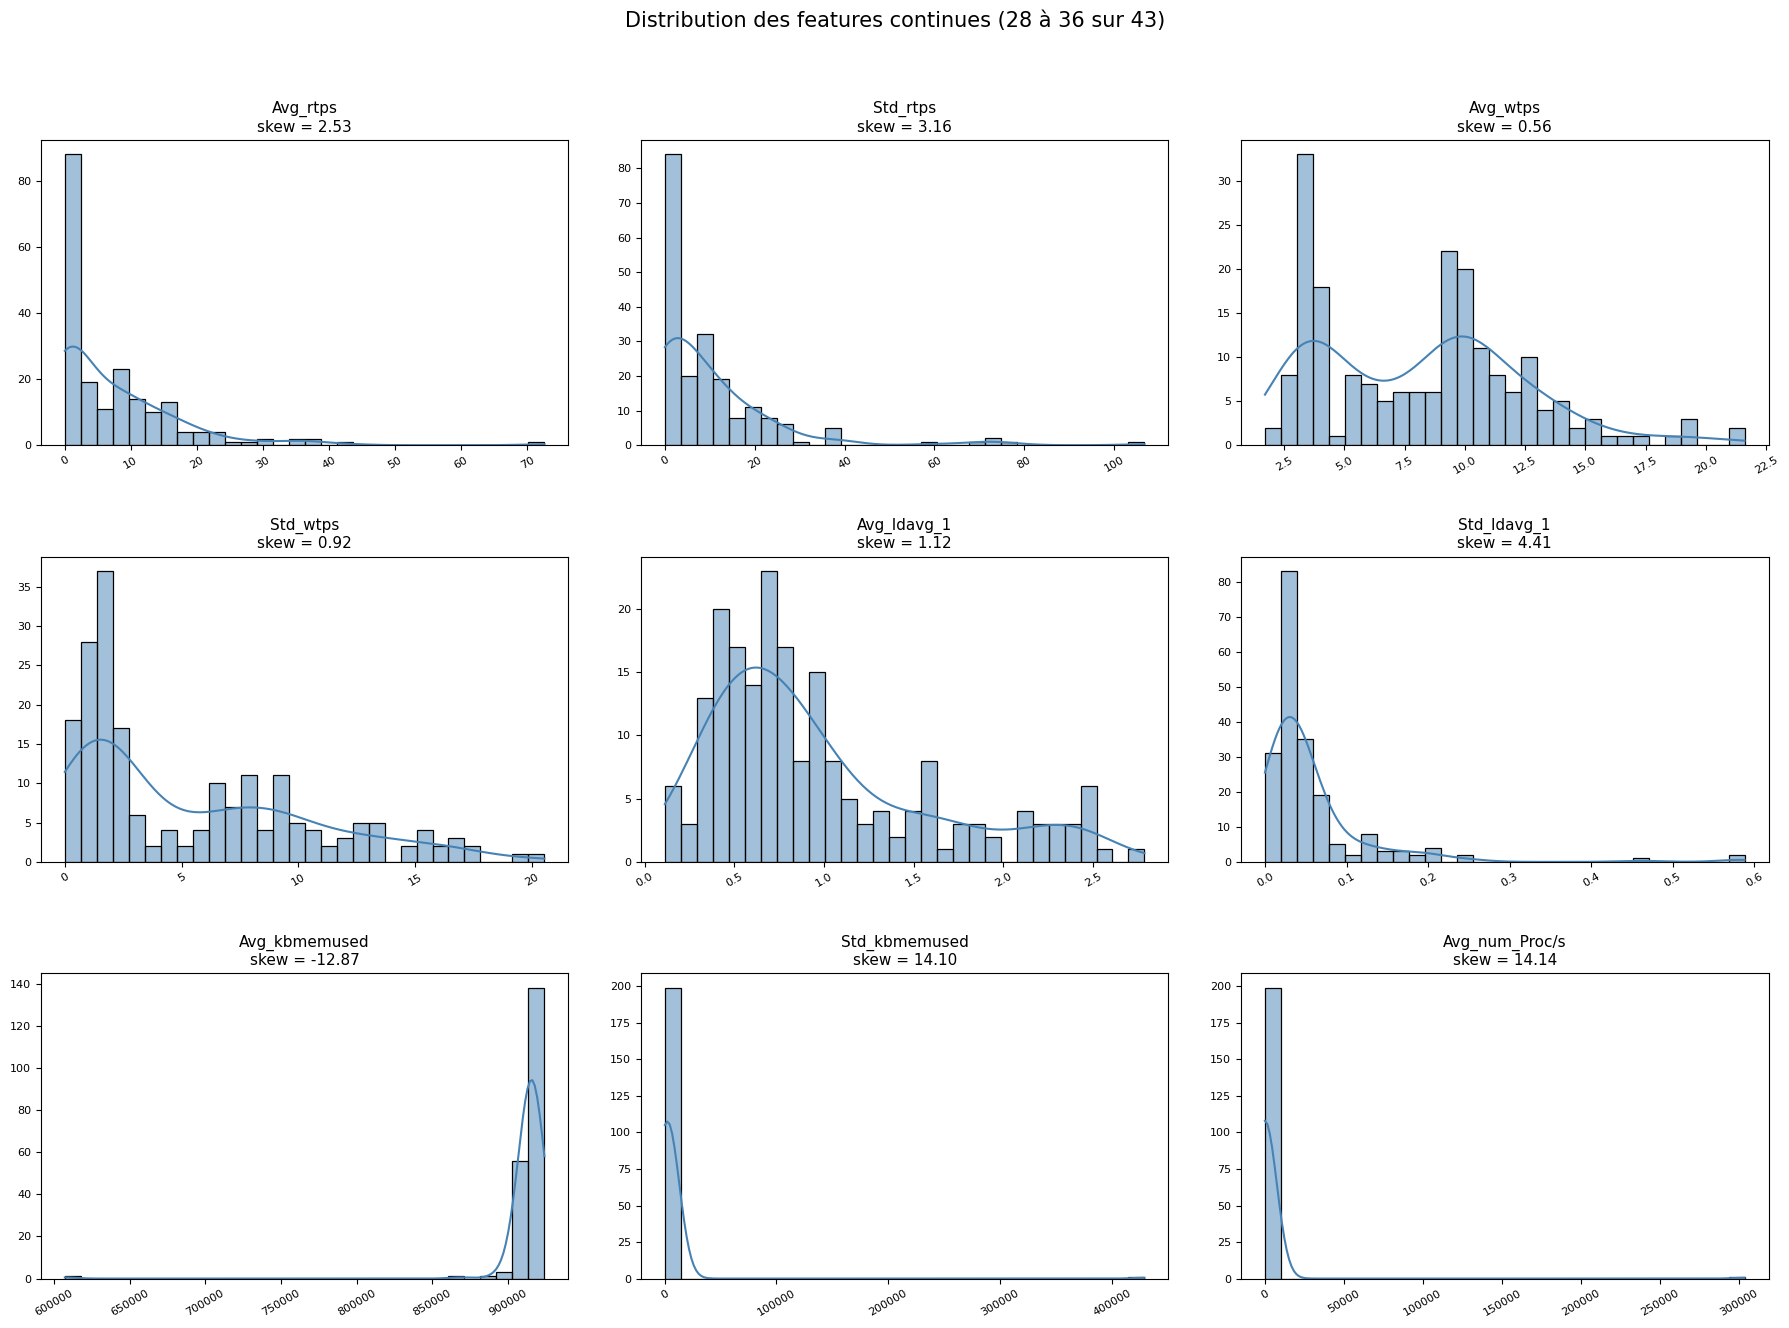

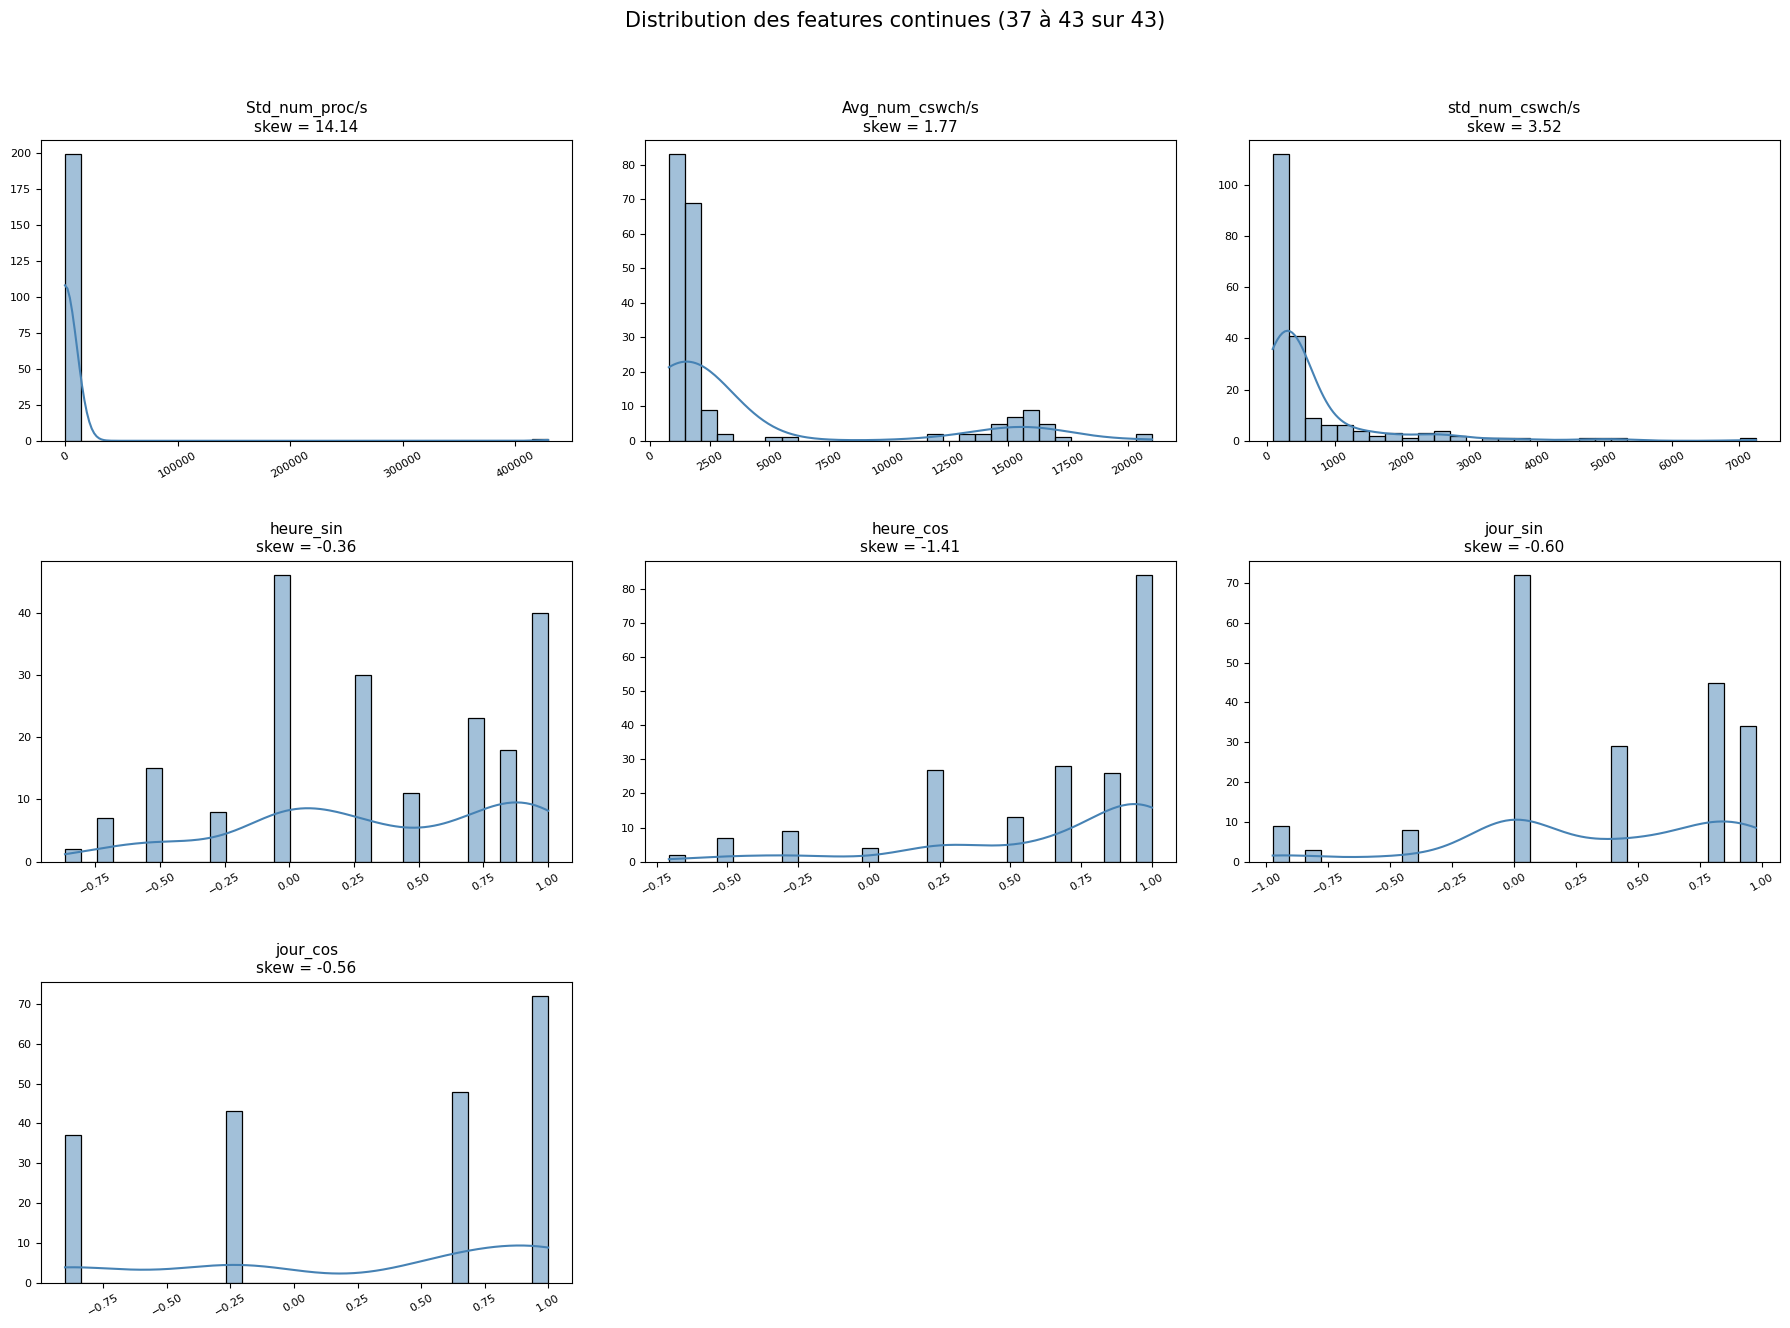

In [16]:
# Histogramme + courbe de densité pour chaque feature continue, avec son skew dans le titre
def tracer_hist(ax, c):
    sns.histplot(X[c].dropna(), kde=True, bins=30, ax=ax, color="steelblue")
    ax.set_title(f"{c}\nskew = {X[c].skew():.2f}", fontsize=11)
    ax.set_xlabel("")
    ax.set_ylabel("")

grille(cont, tracer_hist, "Distribution des features continues")

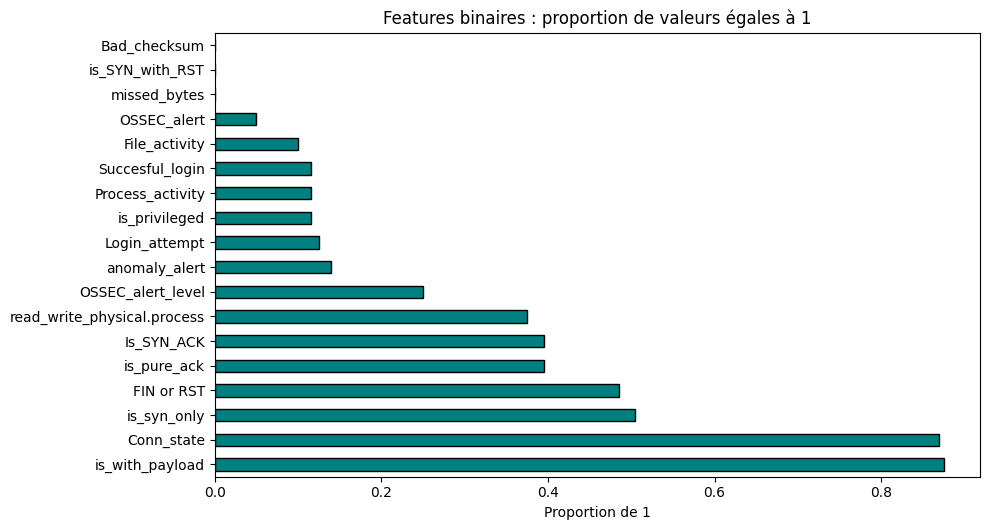

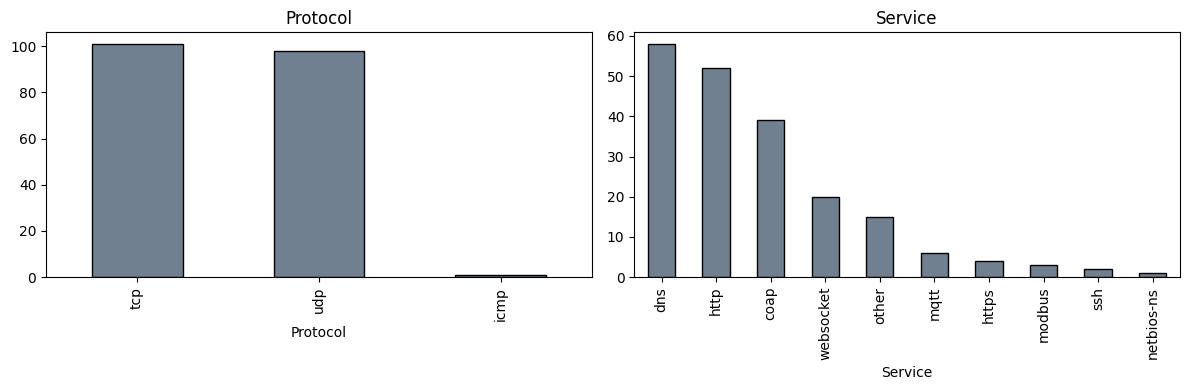

In [17]:
# Binaires : proportion de 0 et de 1
if len(binaires) > 0:
    prop = X[binaires].mean().sort_values(ascending=False).round(3)
    plt.figure(figsize=(10, max(3, 0.3 * len(prop))))
    prop.plot(kind="barh", color="teal", edgecolor="k")
    plt.xlabel("Proportion de 1")
    plt.title("Features binaires : proportion de valeurs égales à 1")
    plt.tight_layout()
    plt.show()

# Catégorielles : nombre de lignes par modalité
cats = X.select_dtypes(exclude="number").columns.tolist()
fig, axes = plt.subplots(1, len(cats), figsize=(6 * len(cats), 4))
axes = np.array(axes).reshape(-1)
for ax, c in zip(axes, cats):
    X[c].value_counts().plot(kind="bar", ax=ax, color="slategray", edgecolor="k")
    ax.set_title(c)
plt.tight_layout()
plt.show()

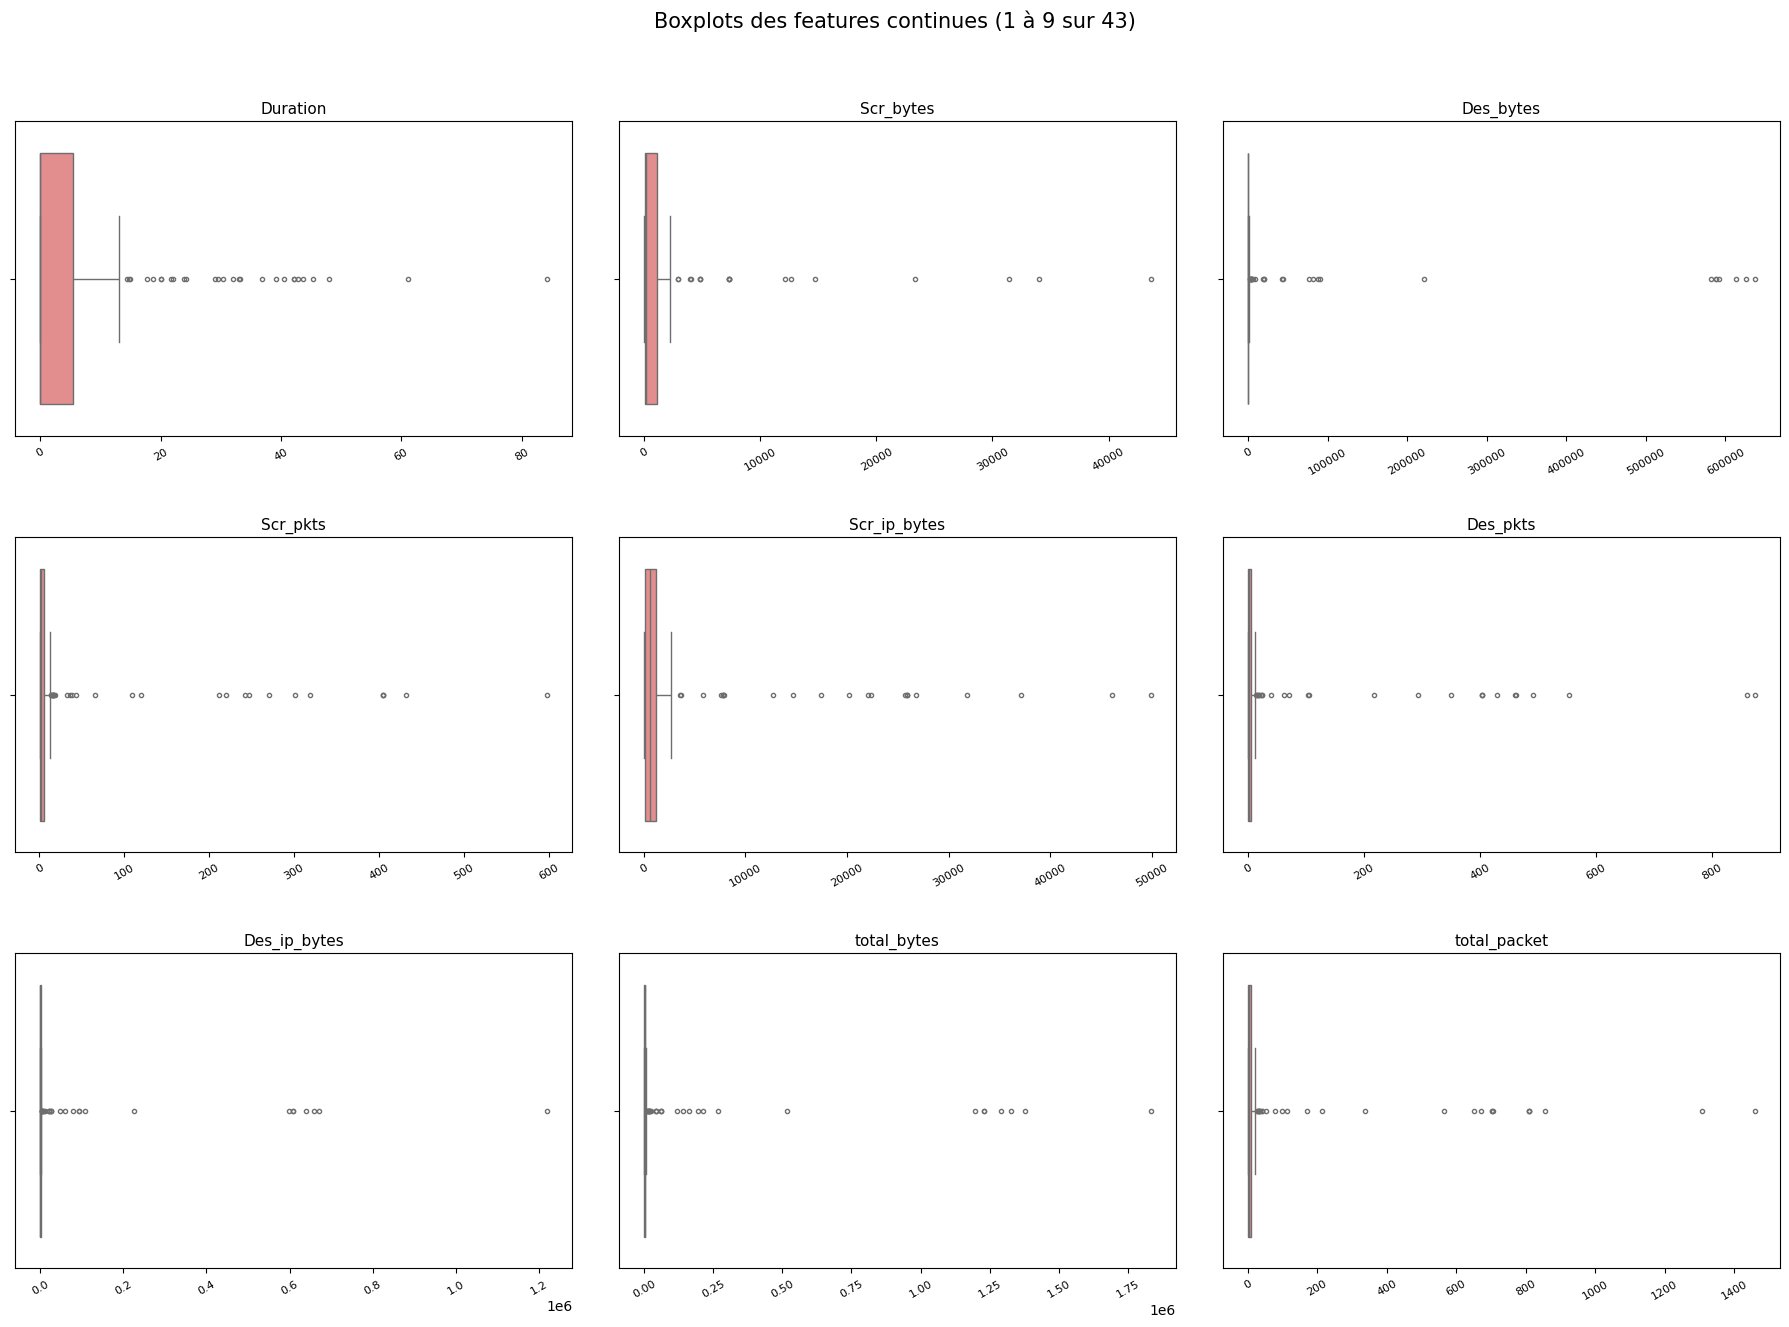

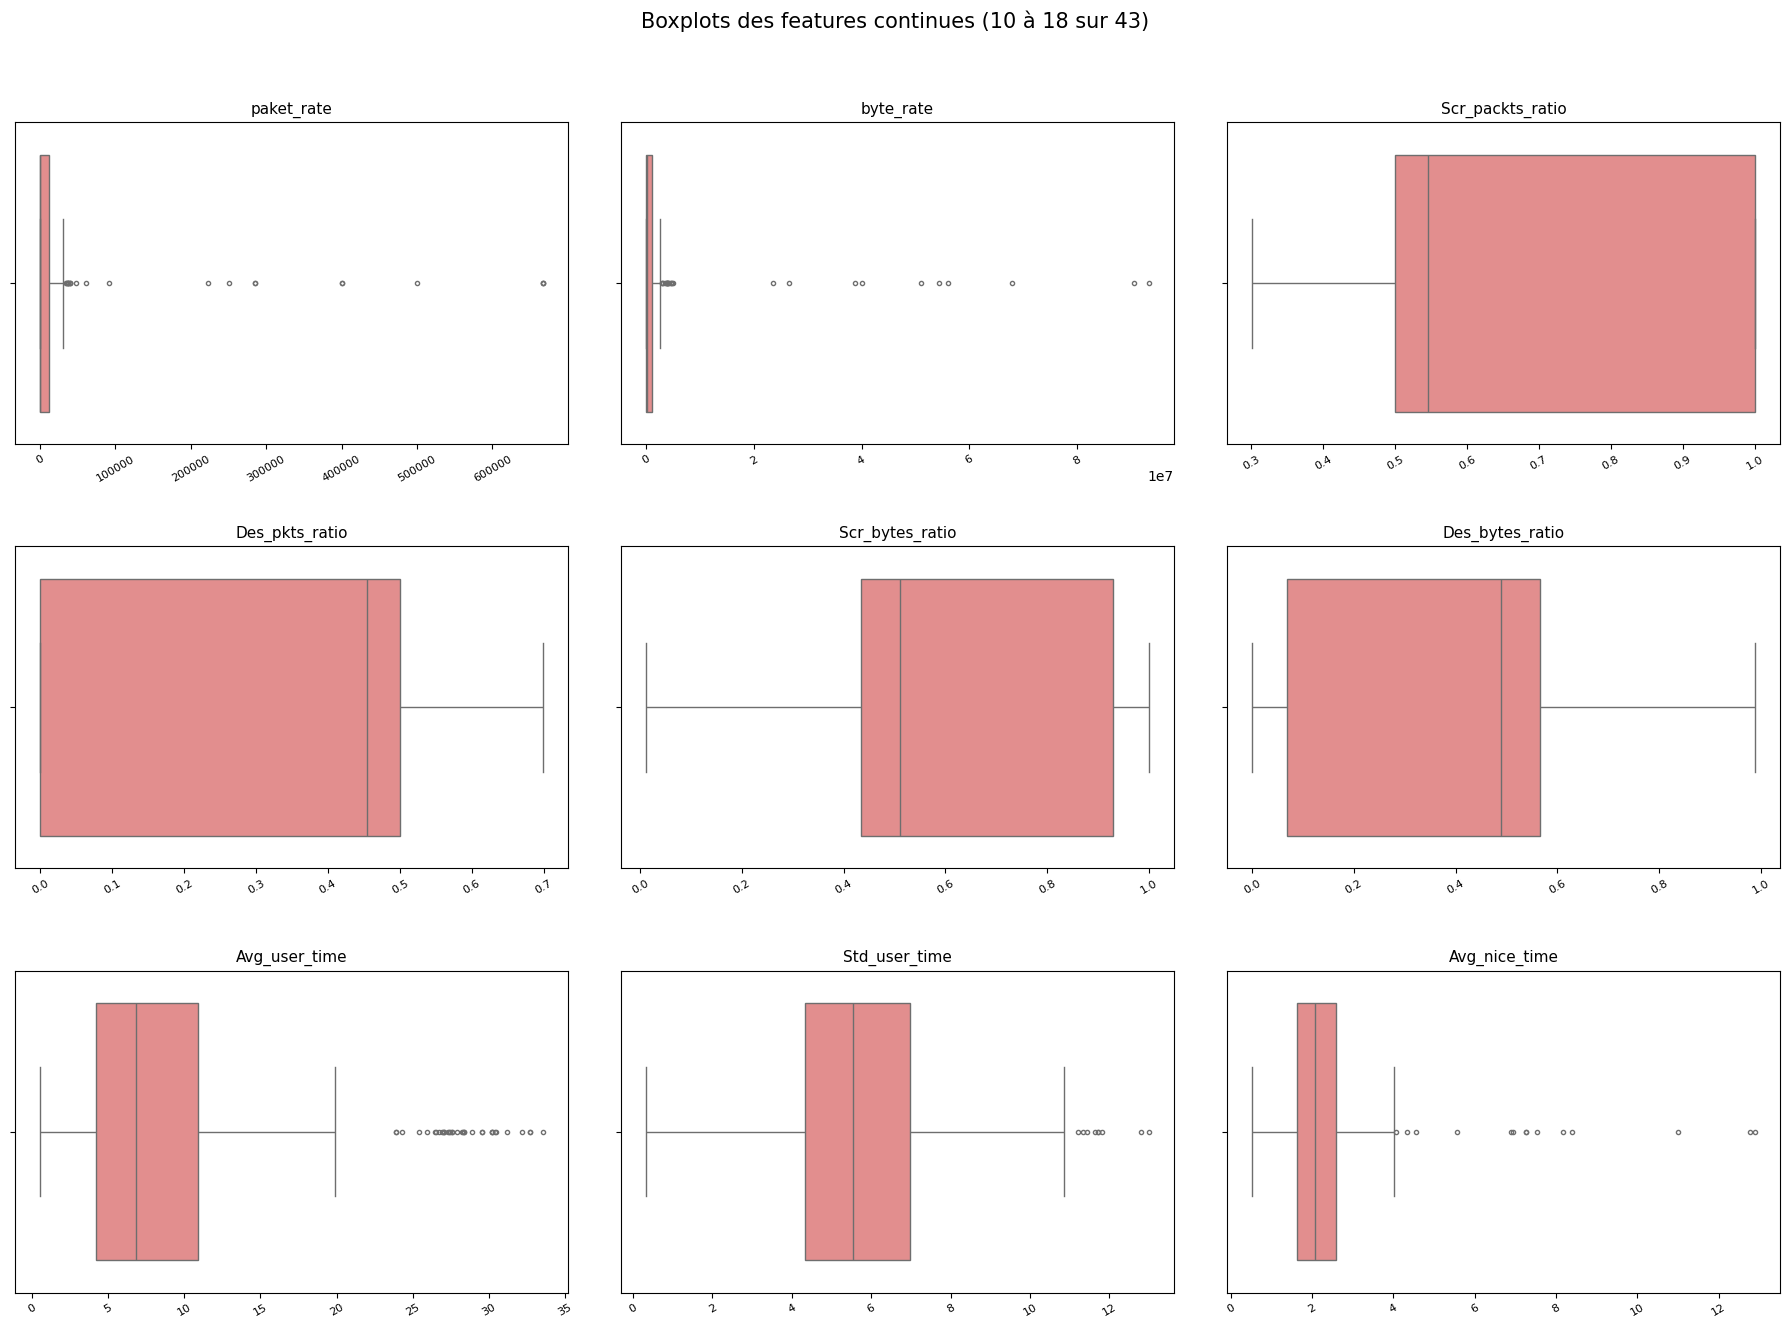

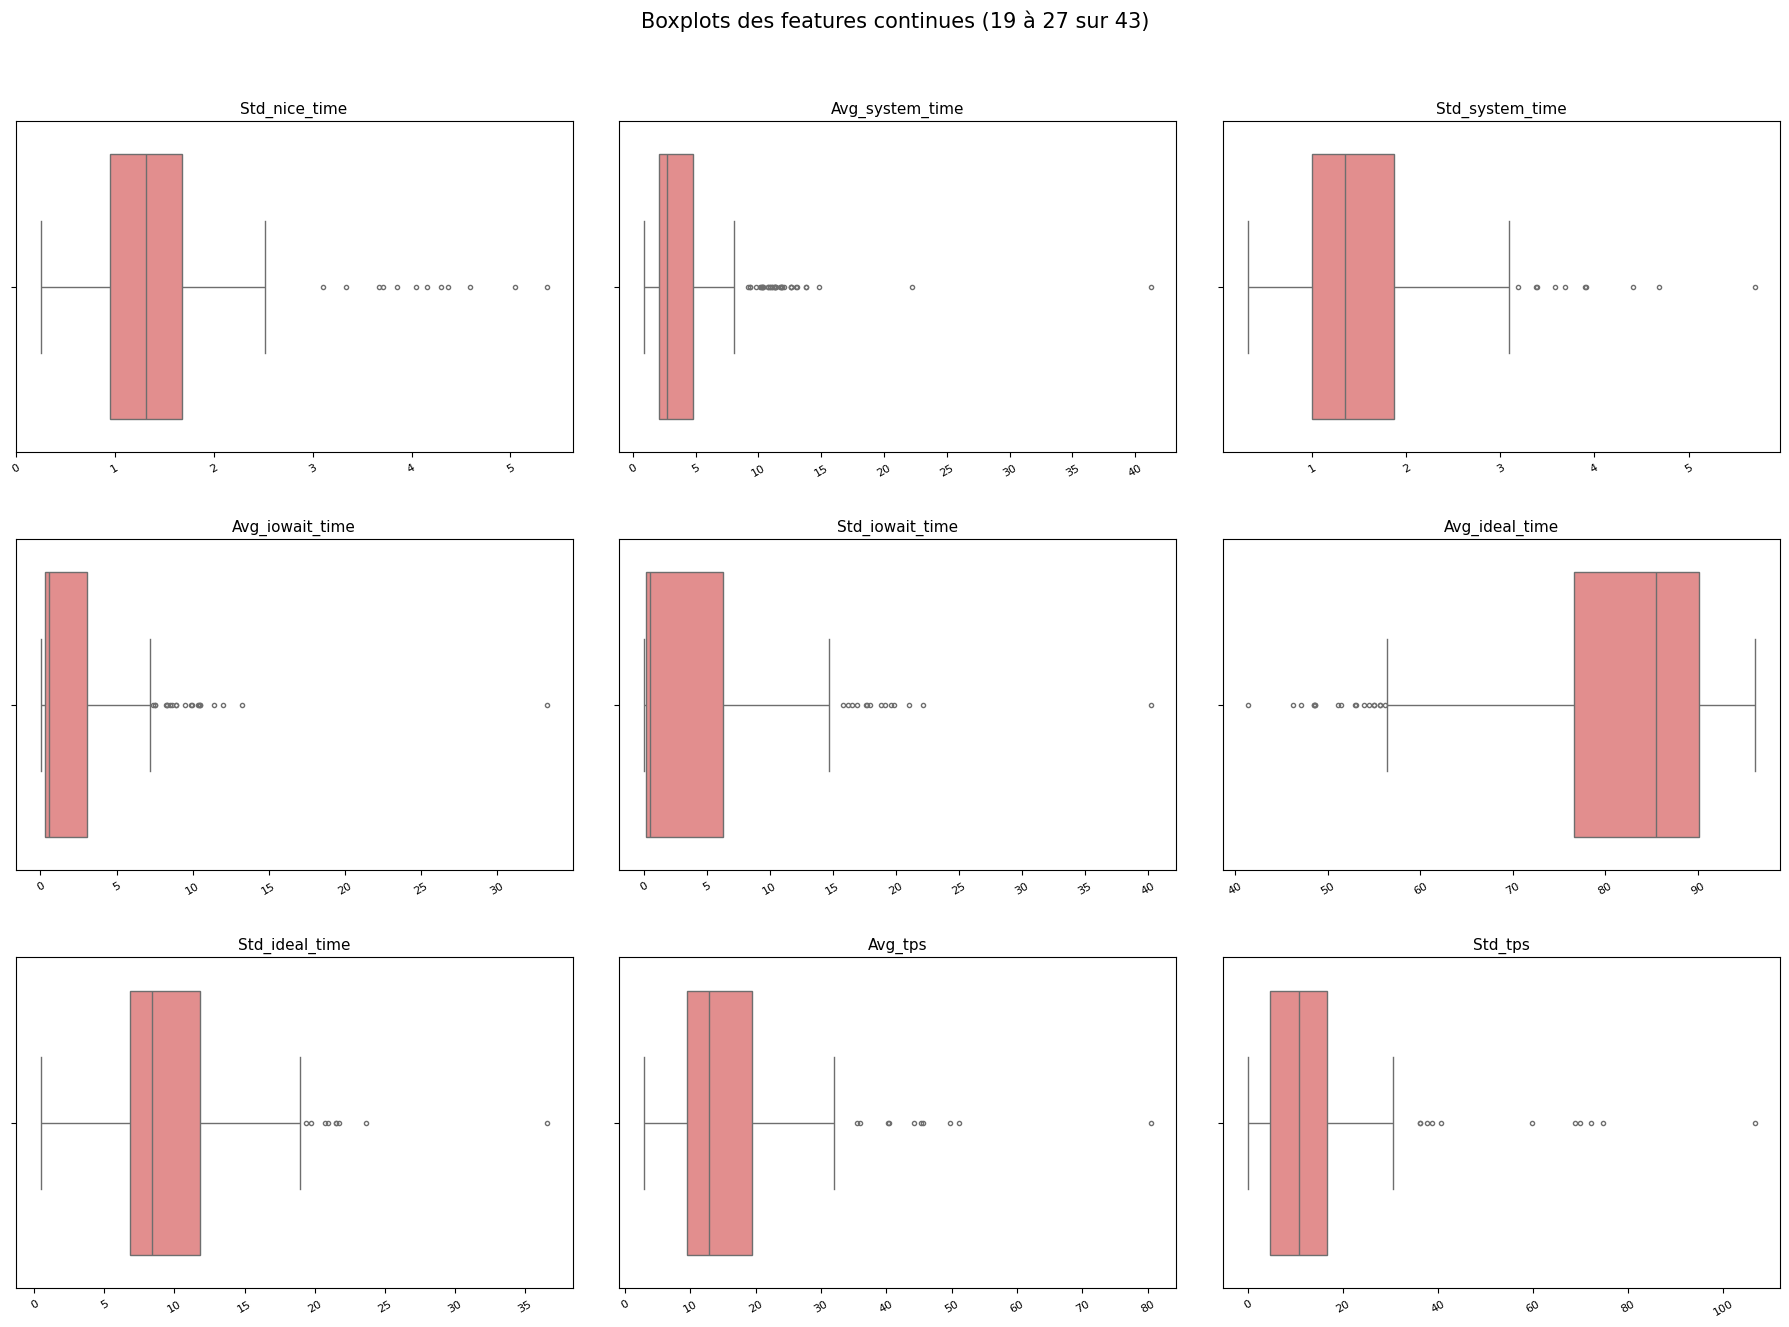

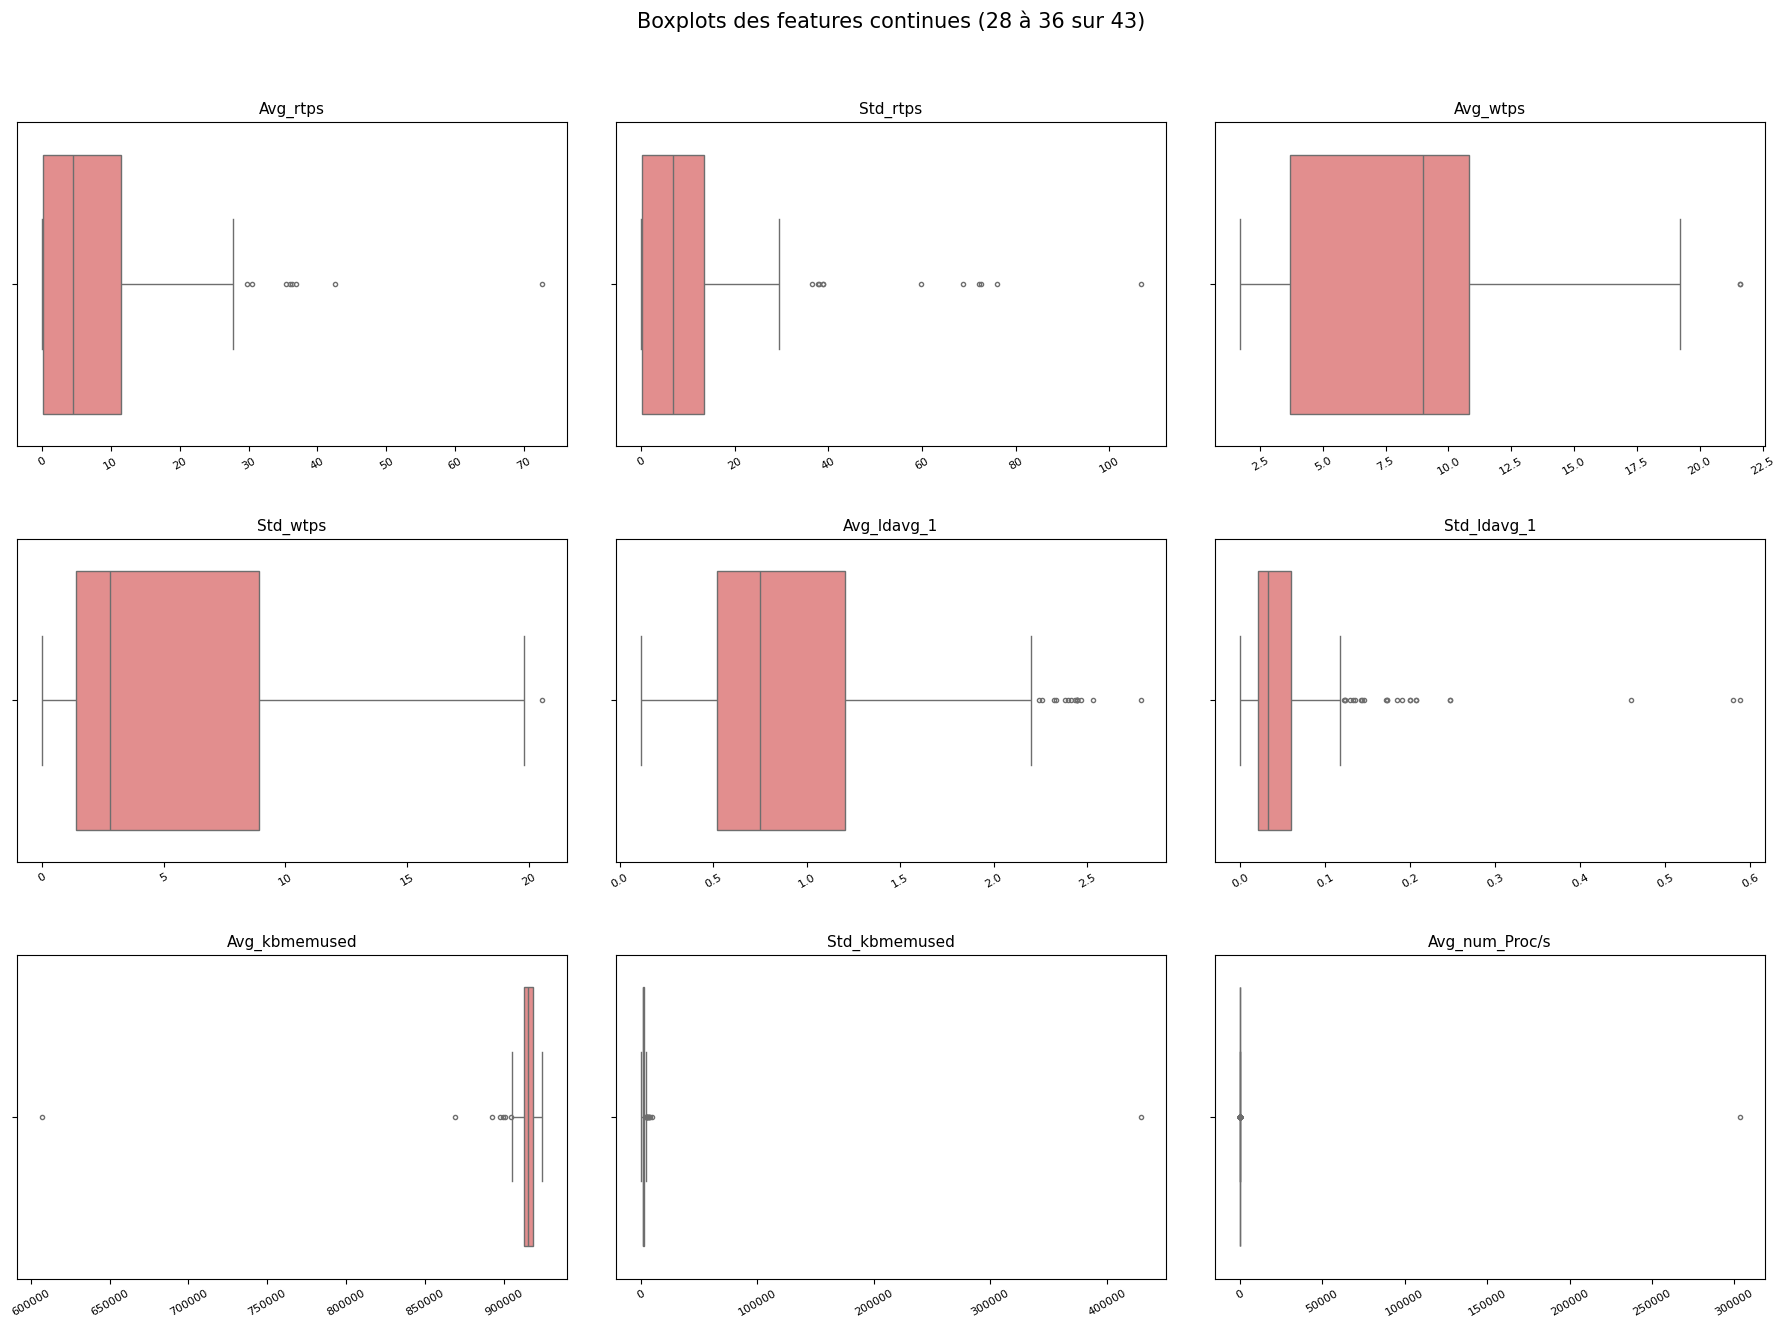

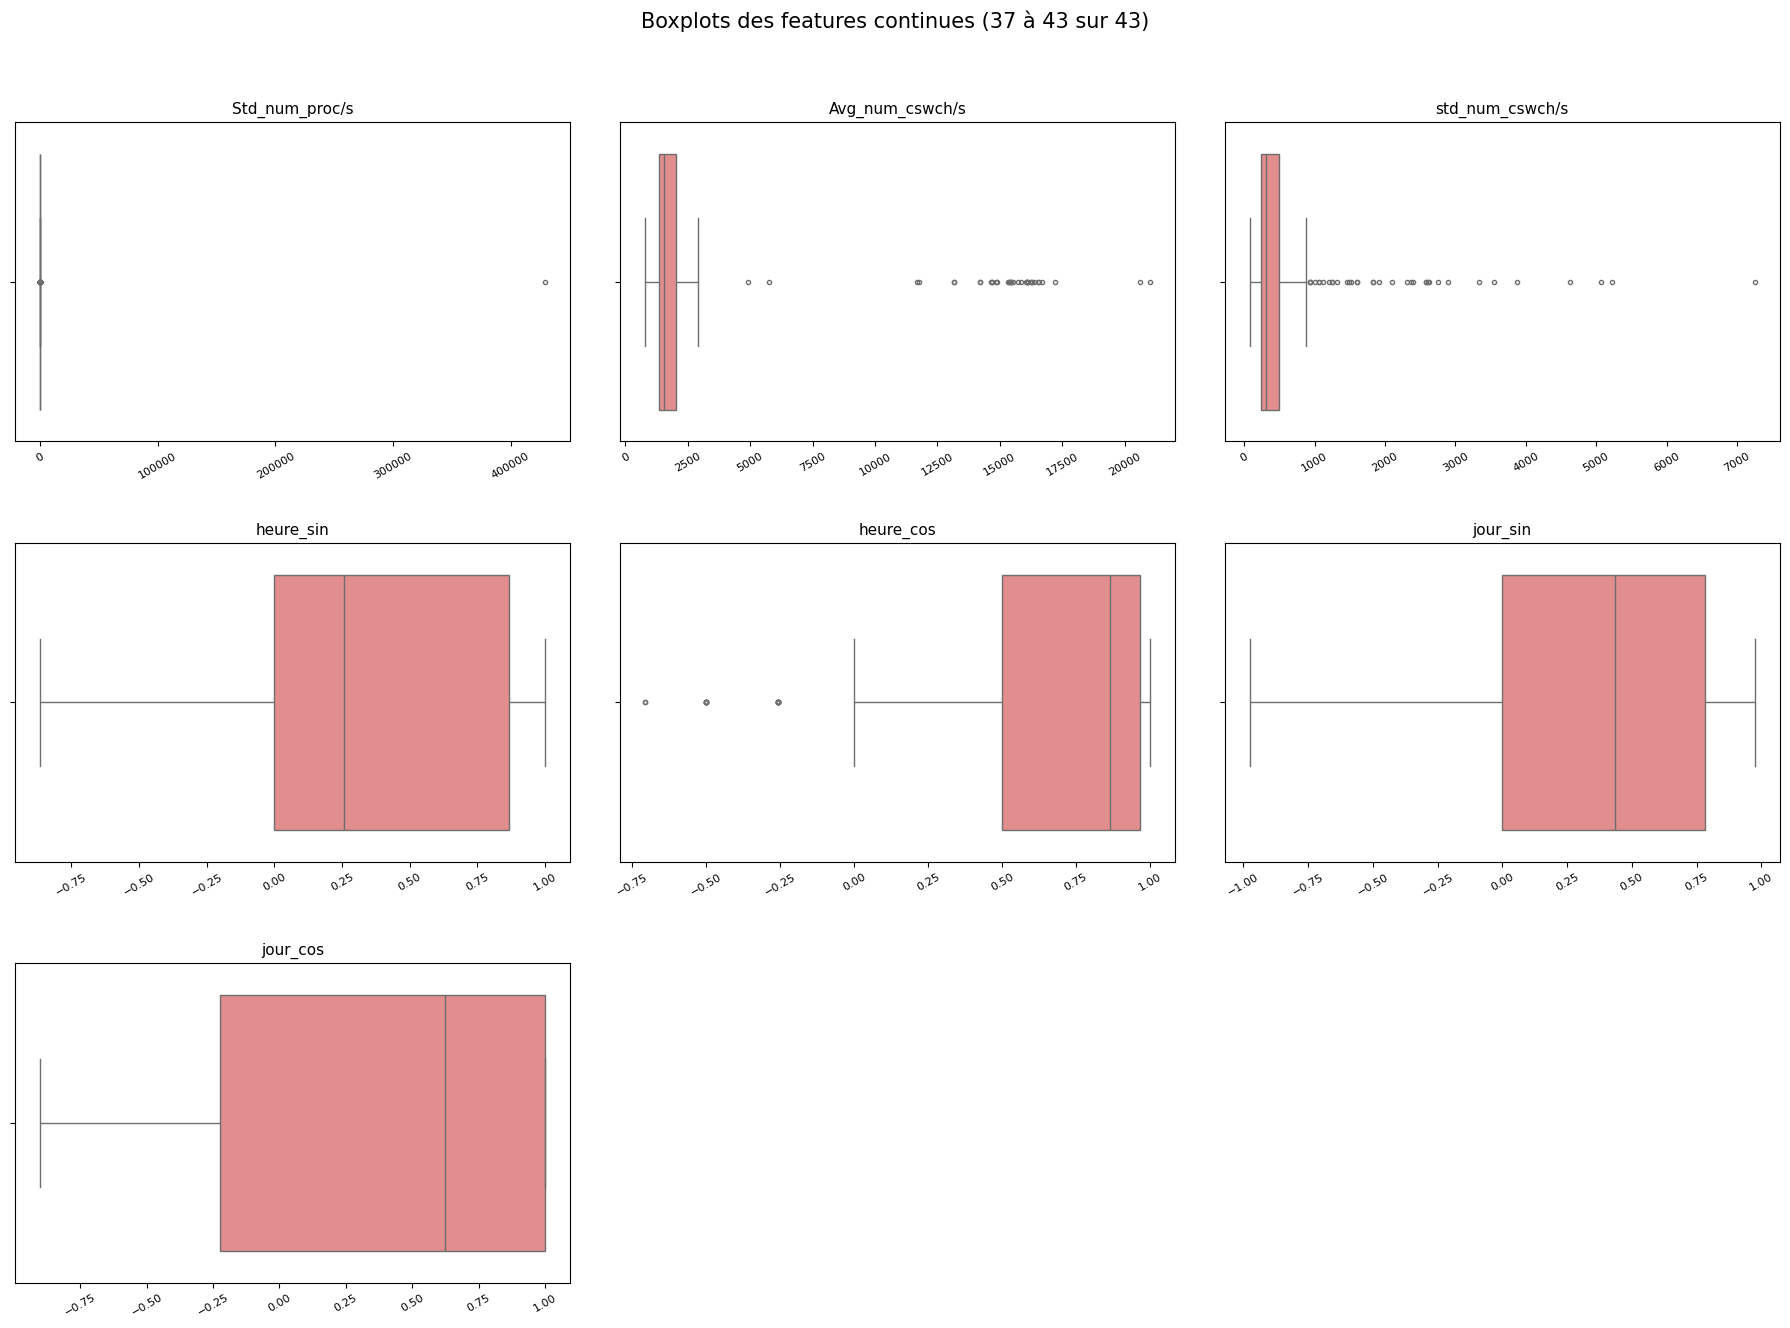

                 Nb valeurs extrêmes  % des lignes
Avg_system_time                   37          18.5
Avg_num_cswch/s                   37          18.5
Std_num_proc/s                    36          18.0
std_num_cswch/s                   36          18.0
Avg_user_time                     35          17.5
Avg_num_Proc/s                    32          16.0
total_bytes                       31          15.5
Scr_pkts                          29          14.5
total_packet                      29          14.5
Duration                          28          14.0
Des_bytes                         28          14.0
Des_ip_bytes                      28          14.0
Des_pkts                          27          13.5
byte_rate                         26          13.0
Scr_ip_bytes                      23          11.5
Std_ldavg_1                       23          11.5
paket_rate                        23          11.5
Avg_iowait_time                   21          10.5
Scr_bytes                      

In [18]:
# Boxplot de chaque feature continue : les points au-delà des moustaches sont des valeurs extrêmes
def tracer_box(ax, c):
    sns.boxplot(x=X[c].dropna(), ax=ax, color="lightcoral", fliersize=3)
    ax.set_title(c, fontsize=11)
    ax.set_xlabel("")

grille(cont, tracer_box, "Boxplots des features continues")

# Règle IQR : une valeur est extrême si elle est hors de [Q1 - 1.5*IQR ; Q3 + 1.5*IQR]
Q1 = X[cont].quantile(0.25)
Q3 = X[cont].quantile(0.75)
IQR = Q3 - Q1
bas = Q1 - 1.5 * IQR
haut = Q3 + 1.5 * IQR

nb_extremes = ((X[cont] < bas) | (X[cont] > haut)).sum()

tab_out = pd.DataFrame({
    "Nb valeurs extrêmes": nb_extremes,
    "% des lignes": (nb_extremes / len(X) * 100).round(1),
}).sort_values("Nb valeurs extrêmes", ascending=False)

print(tab_out[tab_out["Nb valeurs extrêmes"] > 0])

In [19]:
# La cible est class3. class1 et class2 sont retirées de X : elles sont liées à class3
# et donneraient la réponse au modèle (fuite de données).
X = data_small.drop(columns=["class1", "class2", "class3"])
y = data_small["class3"]

print("X :", X.shape, "| y :", y.shape)
print("Colonnes non numériques :", X.select_dtypes(exclude="number").columns.tolist())  # Protocol et Service

X : (200, 63) | y : (200,)
Colonnes non numériques : ['Protocol', 'Service']


In [20]:
# Chaque classe doit avoir au moins 2 lignes pour que stratify fonctionne
stratif = y if y.value_counts().min() >= 2 else None
if stratif is None:
    print("ATTENTION : une classe a moins de 2 lignes, séparation non stratifiée.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=stratif
)
print("Train :", X_train.shape, "| Test :", X_test.shape)

Train : (160, 63) | Test : (40, 63)


In [21]:
# Indicateurs de valeurs manquantes (très recommandé) : le fait qu'une valeur manque est une information.
# J'en crée UN PAR GROUPE (3) et non un par colonne (15) : les colonnes d'un même groupe manquent
# exactement sur les mêmes lignes, donc 15 indicateurs seraient identiques (multicolinéarité).
# Ils sont calculés ligne par ligne : pas de fuite de données. Ils doivent être créés AVANT l'imputation.
groupes = {"octets": grp_A, "paquets": grp_B, "duration": grp_C}

for nom, cols_g in groupes.items():
    X_train[f"{nom}_was_missing"] = X_train[cols_g].isnull().any(axis=1).astype(int)
    X_test[f"{nom}_was_missing"] = X_test[cols_g].isnull().any(axis=1).astype(int)

print("Indicateurs créés :", [c for c in X_train.columns if "was_missing" in c])

Indicateurs créés : ['octets_was_missing', 'paquets_was_missing', 'duration_was_missing']


In [22]:
cat_features = ["Protocol", "Service"]
num_features = [c for c in X_train.columns if c not in cat_features]

print("Numériques :", len(num_features), "| Catégorielles :", len(cat_features))
print("Manquants dans X_train avant imputation :", X_train.isnull().sum().sum())

Numériques : 64 | Catégorielles : 2
Manquants dans X_train avant imputation : 426


In [23]:
# Imputation numérique : médiane (robuste aux valeurs extrêmes).
# fit sur Train uniquement, puis transform sur Train et Test.
X_train_med = X_train.copy()
X_test_med = X_test.copy()

num_imputer = SimpleImputer(strategy="median")
X_train_med[num_features] = num_imputer.fit_transform(X_train_med[num_features])
X_test_med[num_features] = num_imputer.transform(X_test_med[num_features])

# Imputation catégorielle : valeur la plus fréquente (mode)
cat_imputer = SimpleImputer(strategy="most_frequent")
X_train_med[cat_features] = cat_imputer.fit_transform(X_train_med[cat_features])
X_test_med[cat_features] = cat_imputer.transform(X_test_med[cat_features])

print("Imputation médiane terminée")
print("Manquants restants train :", X_train_med.isnull().sum().sum())
print("Manquants restants test  :", X_test_med.isnull().sum().sum())

Imputation médiane terminée
Manquants restants train : 0
Manquants restants test  : 0


In [24]:
# KNN utilise des distances : je mets d'abord les colonnes à la même échelle (RobustScaler ignore les NaN).
# Un trou est rempli par la moyenne des 5 lignes les plus proches.
# Les valeurs numériques obtenues sont donc à l'échelle du RobustScaler.
X_train_knn = X_train.copy()
X_test_knn = X_test.copy()

scaler_knn = RobustScaler()
X_train_knn[num_features] = scaler_knn.fit_transform(X_train_knn[num_features])
X_test_knn[num_features] = scaler_knn.transform(X_test_knn[num_features])

knn_imputer = KNNImputer(n_neighbors=5)
X_train_knn[num_features] = knn_imputer.fit_transform(X_train_knn[num_features])
X_test_knn[num_features] = knn_imputer.transform(X_test_knn[num_features])

# Catégories : valeur la plus fréquente, comme pour la médiane
cat_imputer_knn = SimpleImputer(strategy="most_frequent")
X_train_knn[cat_features] = cat_imputer_knn.fit_transform(X_train_knn[cat_features])
X_test_knn[cat_features] = cat_imputer_knn.transform(X_test_knn[cat_features])

print("Imputation KNN terminée")
print("Manquants restants train :", X_train_knn.isnull().sum().sum())
print("Manquants restants test  :", X_test_knn.isnull().sum().sum())

Imputation KNN terminée
Manquants restants train : 0
Manquants restants test  : 0


In [27]:
data_small.describe()

,Duration,Scr_bytes,Des_bytes,Conn_state,missed_bytes,is_syn_only,Is_SYN_ACK,is_pure_ack,is_with_payload,FIN or RST,Bad_checksum,is_SYN_with_RST,Scr_pkts,Scr_ip_bytes,Des_pkts,Des_ip_bytes,anomaly_alert,total_bytes,total_packet,paket_rate,byte_rate,Scr_packts_ratio,Des_pkts_ratio,Scr_bytes_ratio,Des_bytes_ratio,Avg_user_time,Std_user_time,Avg_nice_time,Std_nice_time,Avg_system_time,Std_system_time,Avg_iowait_time,Std_iowait_time,Avg_ideal_time,Std_ideal_time,Avg_tps,Std_tps,Avg_rtps,Std_rtps,Avg_wtps,Std_wtps,Avg_ldavg_1,Std_ldavg_1,Avg_kbmemused,Std_kbmemused,Avg_num_Proc/s,Std_num_proc/s,Avg_num_cswch/s,std_num_cswch/s,OSSEC_alert,OSSEC_alert_level,Login_attempt,Succesful_login,File_activity,Process_activity,read_write_physical.process,is_privileged,heure_sin,heure_cos,jour_sin,jour_cos
count,186.000000,154.000000,154.000000,200.000000,200.0,200.00000,200.000000,200.000000,200.000000,200.000000,200.0,200.0,168.000000,168.000000,168.000000,1.680000e+02,200.000000,1.540000e+02,168.000000,154.000000,1.540000e+02,168.000000,168.000000,154.000000,154.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000
mean,6.214123,1901.753247,32427.175325,0.870000,0.0,0.50500,0.395000,0.395000,0.875000,0.485000,0.0,0.0,30.267857,3250.934524,41.892857,3.526371e+04,0.140000,7.629812e+04,72.160714,35131.424584,4.213623e+06,0.655704,0.344296,0.600314,0.399686,10.257303,5.810109,2.455453,1.462969,4.602975,1.549846,2.319810,4.028530,80.365205,9.485121,15.648995,13.271099,7.378608,10.218006,8.270387,5.409649,0.963792,0.057088,913334.456600,4549.957586,1518.704405,2146.888272,4031.892117,671.413419,0.050000,0.250000,0.125000,0.115000,0.100000,0.115000,0.375000,0.115000,0.338187,0.656327,0.331608,0.295116
std,13.118561,5699.199722,127137.470720,0.337147,0.0,0.50123,0.490077,0.490077,0.331549,0.501029,0.0,0.0,91.613381,8179.382207,137.319813,1.500438e+05,0.347858,2.886338e+05,226.480078,115035.159028,1.450654e+07,0.226218,0.226218,0.305961,0.305961,8.993106,2.461502,1.757318,0.848564,4.547723,0.837664,3.710314,6.060382,13.581545,4.740503,10.312986,14.000738,9.758584,14.938848,4.256443,4.964284,0.621473,0.076695,22478.055828,30217.354030,21455.772873,30342.807339,5414.236864,987.284414,0.218492,1.092459,0.331549,0.319823,0.300753,0.319823,0.485338,0.319823,0.519760,0.432435,0.526599,0.727785
min,0.000003,0.000000,0.000000,0.000000,0.0,0.00000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,1.000000,38.000000,0.000000,0.000000e+00,0.000000,8.400000e+01,1.000000,0.046726,2.793560e+01,0.301565,0.000000,0.011833,0.000000,0.533000,0.332116,0.529000,0.255517,0.937000,0.317578,0.026000,0.078000,41.376000,0.464479,2.997000,0.000000,0.000000,0.000000,1.700000,0.000000,0.113000,0.000000,607124.120000,134.319619,0.000000,0.000000,787.800000,81.808863,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.866025,-0.707107,-0.974928,-0.900969
25%,0.000208,58.250000,0.000000,1.000000,0.0,0.00000,0.000000,0.000000,1.000000,0.000000,0.0,0.0,1.000000,133.000000,0.000000,0.000000e+00,0.000000,2.200000e+02,2.000000,5.356387,2.337495e+03,0.500000,0.000000,0.434309,0.069467,4.229750,4.323876,1.631500,0.952415,2.098750,0.997880,0.278500,0.197222,76.592000,6.847115,9.475000,4.671586,0.100000,0.300000,3.700000,1.417745,0.517500,0.021581,912995.200000,1624.632338,0.500000,0.400000,1329.400000,238.022038,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.000000,-0.222521
50%,0.011364,156.000000,72.000000,1.000000,0.0,1.00000,0.000000,0.000000,1.000000,0.000000,0.0,0.0,2.000000,590.000000,1.000000,1.000000e+02,0.000000,1.685000e+03,3.000000,653.201623,1.590640e+05,0.545455,0.454545,